# 03 · Kidney segmentation

## Introduction

### Goal
The first step of our system is to **outline the kidney automatically** in an ultrasound image. The outline tells
the rest of the pipeline *where the kidney is*:

- **Lesions are searched inside it.** In our data almost every lesion box (98.7 %) lies inside the kidney outline,
  so the outline defines the region where cysts, stones or hydronephrosis can appear.
- **The classifier can focus on it.** A crop around the kidney is the input of the kidney-focused classifier.
- **Explanations can be checked against it.** We can measure whether the classifier's attention (Grad-CAM) falls
  on the kidney or on the background.
- **It gives the kidney size**, a sign of chronic kidney disease.

### Task design
- **Data.** We train and test on dataset A (`bbdd_kidney/`, 1,985 images from Hospital Ramón y Cajal), the same
  data as the URI-CADS baseline [24]. Each image has a kidney outline drawn by nephrologists (`.mat` file), which
  is our target.
- **Preprocessing.** Every image is converted to grayscale, padded to a square so the kidney keeps its shape,
  resized to 512 × 512 and scaled in intensity (1st–99th percentile). During training only, we apply random
  rotation, shift, zoom, contrast changes and noise to the image and its outline together.
- **5-fold cross-validation.** We use the team's split from the EDA (`results/eda/folds.csv`). It keeps
  near-duplicate images in the same fold, so the model is never tested on a copy of an image it trained on. In
  each of the 5 repetitions, 3 folds train, 1 fold is used to choose when to stop training, and 1 fold tests.
  Every image is tested exactly once, by a model that has never seen it.
- **External test.** To check that the models work beyond one hospital, we use **KidneyUS** [18]: 534 images from
  another hospital and several scanners. It has outlines of the whole kidney (the capsule) and of three inner
  structures (cortex, medulla, central echo complex), drawn by two sonographers. It has **no pathology labels and
  no lesion boxes**, so we use it only to test the kidney outline, never for training.

### Methods
We compare three families of models:

| | Method | Idea |
|---|---|---|
| A | **U-Net** and **DeepLabV3+**, trained on our data | Standard segmentation networks [S18], [S19]; DeepLabV3+ is also the reference model in URI-CADS |
| B | **MedSAM** [S3] and **UltraSam** [S1], no training | Foundation models that outline "the object inside a box"; we give them a box around the kidney |
| C | **MedSAM with its decoder fine-tuned** on our data | Adapts MedSAM to our images and outline style in minutes per fold |

All code lives in `src/kidney/` (one module per step: data loading, split, training, prompting, external test,
metrics). This notebook calls those functions. All results are saved as CSV files in `results/segmentation/`
(one score per image and per model), together with the predicted outlines (`results/pred_masks/`), so every
number in this notebook can be recomputed without retraining.

### Baseline and how we measure
Our baseline is **URI-CADS** [24], the published system built on the same 1,985 images. We compare our outlines
with the nephrologists' outlines using two overlap scores, both computed **per image** and then **averaged over
all test images**:

- **Dice**: 2 × overlap ÷ (size of our outline + size of the doctor's outline). 1 = identical, 0 = no overlap.
- **IoU** (intersection over union): overlap ÷ everything covered by either outline. Stricter than Dice; the same
  outline always gets a lower IoU.

We also report **HD95**, the distance in pixels between the two borders at their worst point (95th percentile).
It catches mistakes, such as a stray piece far from the kidney, that hardly change Dice.

| Baseline [24] | Dice (average, %) | IoU (average, %) |
|---|---|---|
| URI-CADS, segmentation-only model | **91.23** | **84.99** |
| URI-CADS, full system | 89.38 | 81.41 |
| DeepLabV3+ trained by URI-CADS | 89.34 | 81.80 |

**Our target** is an average Dice above **91.23 %** on dataset A, and at least **85 %** on KidneyUS, the value
published for that dataset [18].

In [1]:
# ---- Settings -------------------------------------------------------------
RUN_PIPELINE = False   # False: load committed results (fast, CPU). True: retrain everything (GPU, ~8 h)
SMOKE = False          # with RUN_PIPELINE=True: quick end-to-end check on a tiny subset
BRANCH = "segmentation"
REPO_URL = "https://github.com/Noadori34/Project-data-science.git"

In [2]:
# ---- Find or clone the repository -------------------------------------------
import os, sys, subprocess
from pathlib import Path

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "kidney").is_dir()), None)
if root is None:                                   # e.g. a fresh Colab session
    root = Path("/content/Project-data-science")
    if not root.exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
os.chdir(root)
sys.path.insert(0, str(root / "src"))
os.environ["PYTHONPATH"] = str(root / "src")
if RUN_PIPELINE:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-r", "requirements-seg.txt"], check=True)
print("Repository:", root)

Repository: /home/claude/noadori34/project-data-science


In [3]:
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display, Image as ShowImage

# Our project code (src/kidney)
from kidney import config as C
from kidney.data import (list_dataset_a, load_image_a, load_mask_a, load_label_a,
                         list_dataset_b, load_image_b, load_capsule_b, mask_to_box)
from kidney.splits import read_folds, fold_roles
from kidney.metrics import dice, iou, hd95, mean_sd, bootstrap_ci
from kidney.seg_common import letterbox, postprocess
from kidney.prepare_masks import overlay
from kidney.report_seg import results_table

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SMK = "--smoke" if SMOKE else ""

def show(images, titles, ncols=4, size=4):
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 0.75 * nrows))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, im, t in zip(np.atleast_1d(axes).ravel(), images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
        ax.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

MODEL_NAMES = {
    "unet_r34": "U-Net ResNet-34", "deeplabv3p_r50": "DeepLabV3+ ResNet-50",
    "medsam_gt": "MedSAM, true box", "medsam_auto": "MedSAM, automatic box",
    "ultrasam_gt": "UltraSam, true box", "ultrasam_auto": "UltraSam, automatic box",
    "medsam_ft_gt": "MedSAM fine-tuned, true box", "medsam_ft_auto": "MedSAM fine-tuned, automatic box",
}

In [4]:
# ---- Extra helpers for the figures in this notebook -------------------------
PALETTE = {"deeplabv3p_r50": "#1f6f78", "unet_r34": "#4a9a9f", "medsam_ft_auto": "#c9a227",
           "ultrasam_auto": "#8e6bb0", "medsam_auto": "#c0504d", "medsam_ft_gt": "#e6cf7a",
           "ultrasam_gt": "#c3b1d9", "medsam_gt": "#e8a5a3"}

def load_pred(model, iid):
    """Out-of-fold predicted outline saved by the pipeline (results/pred_masks/<model>/<id>.png)."""
    return (cv2.imread(str(C.PRED_MASKS / model / f"{iid}.png"), cv2.IMREAD_GRAYSCALE) > 0).astype(np.uint8)

def error_overlay(img, gt, pred, box=None, box2=None):
    """Colour every pixel by what happened: green = correct kidney, red = predicted but not kidney
    (over-segmentation), blue = kidney that was missed (under-segmentation)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB).astype(np.float32)
    g, p = gt.astype(bool), pred.astype(bool)
    for m, col in [(g & p, (40, 200, 70)), (p & ~g, (230, 50, 50)), (g & ~p, (40, 110, 240))]:
        rgb[m] = 0.45 * rgb[m] + 0.55 * np.array(col)
    rgb = rgb.astype(np.uint8)
    for b, col in [(box, (255, 255, 255)), (box2, (255, 210, 0))]:
        if b is not None:
            cv2.rectangle(rgb, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), col, 2)
    return rgb

def show_rgb(images, titles, ncols=4, size=4, suptitle=None):
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 0.85 * nrows))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, im, t in zip(np.atleast_1d(axes).ravel(), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else "gray"); ax.set_title(t, fontsize=9)
    if suptitle: fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(h_pad=2.0); plt.show()

ERROR_LEGEND = "green = correct kidney · red = drawn but not kidney · blue = kidney that was missed"

def resize_to(m, size=128):
    """Letterbox a mask to a square so masks of different sizes can be averaged."""
    out, _ = letterbox(m.astype(np.float32), size)
    return out

## 1. Data

### 1.1 Dataset A: what we segment

Dataset A (`bbdd_kidney/`) is the URI-CADS dataset [24]: 1,985 B-mode kidney images from Hospital Ramón y Cajal (one Toshiba Xario 660a scanner, 2009–2018). Two nephrologists annotated each image with a **kidney outline** (`.mat` file, key `mask`), the diagnosis, two global pathologies and lesion boxes. The kidney outline is our segmentation target.

In [5]:
labels_a = list_dataset_a()           # parses every bbdd_kidney/labels/*.txt
print("Images:", len(labels_a))
summary = pd.DataFrame({
    "images": [len(labels_a), (labels_a.diagnosis == 0).sum(), (labels_a.diagnosis == 1).sum(),
               labels_a.pcd.sum(), labels_a.hc.sum(), (labels_a.view == 1).sum(), (labels_a.n_boxes > 0).sum()]},
    index=["all", "healthy", "pathological", "PCD (poor corticomedullary differentiation)",
           "HC (hyperechoic cortex)", "view 1 (minority view)", "with at least one lesion box"])
summary["share %"] = (100 * summary.images / len(labels_a)).round(1)
summary

Images: 1985


,images,share %
all,1985,100.0
healthy,450,22.7
pathological,1535,77.3
PCD (poor corticomedullary differentiation),595,30.0
HC (hyperechoic cortex),509,25.6
view 1 (minority view),143,7.2
with at least one lesion box,1323,66.6


Below: four images with the reference kidney outline in **green** and the lesion boxes coloured by class (SCY = simple cyst, HYD = hydronephrosis, …, see `config.BOX_CLASSES`).

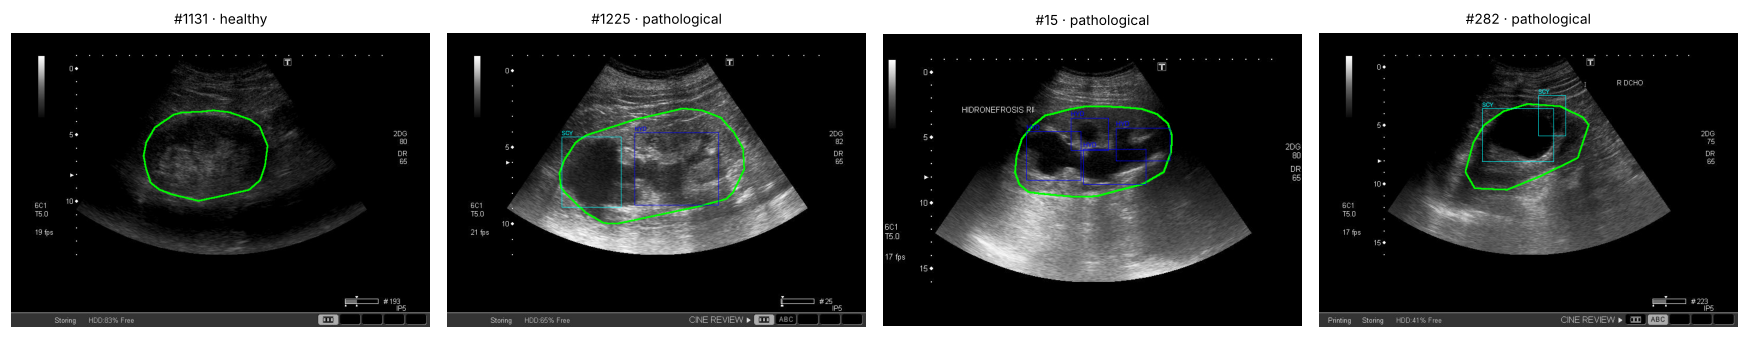

In [6]:
examples = ["1131", "1225", "15", "282"]   # healthy, cyst + hydronephrosis, hydronephrosis, cyst
ims, tts = [], []
for iid in examples:
    lab = load_label_a(iid)
    ims.append(overlay(load_image_a(iid), load_mask_a(iid), lab.boxes))
    tts.append(f"#{iid} · {'pathological' if lab.diagnosis else 'healthy'}")
show(ims, tts)

In [7]:
# Checks on all 1,985 masks (computed by kidney.prepare_masks, saved in results/segmentation/mask_check.csv)
if RUN_PIPELINE:
    subprocess.run([sys.executable, "-m", "kidney.prepare_masks"], check=True)
chk = pd.read_csv(C.SEG_DIR / "mask_check.csv", dtype={"image_id": str})
q = chk.area_frac.quantile([0, .25, .5, .75, 1]) * 100
print(f"Mask size equals image size: {chk.size_match.mean():.0%}")
print(f"Kidney area, % of image: median {q[.5]:.1f} (IQR {q[.25]:.1f}-{q[.75]:.1f}, range {q[0]:.1f}-{q[1]:.1f})")
print(f"Masks with more than one region: {(chk.n_components > 1).sum()}   masks with holes: {(chk.hole_px > 0).sum()}")
print(f"Lesion box centres inside the kidney mask: {chk.boxes_centre_in_mask.sum()} / {chk.n_boxes.sum()} "
      f"({chk.boxes_centre_in_mask.sum() / chk.n_boxes.sum():.1%})")

Mask size equals image size: 100%
Kidney area, % of image: median 7.1 (IQR 5.2-9.2, range 1.1-27.3)
Masks with more than one region: 6   masks with holes: 2
Lesion box centres inside the kidney mask: 2445 / 2478 (98.7%)


**Figure 1.1.** How big the kidney is, and where it sits in the image. Left: kidney area as a share of the image, for healthy and pathological kidneys. Right: all 1,985 reference outlines stacked on top of each other (after padding each image to a square); the brighter a pixel, the more often it belongs to the kidney.

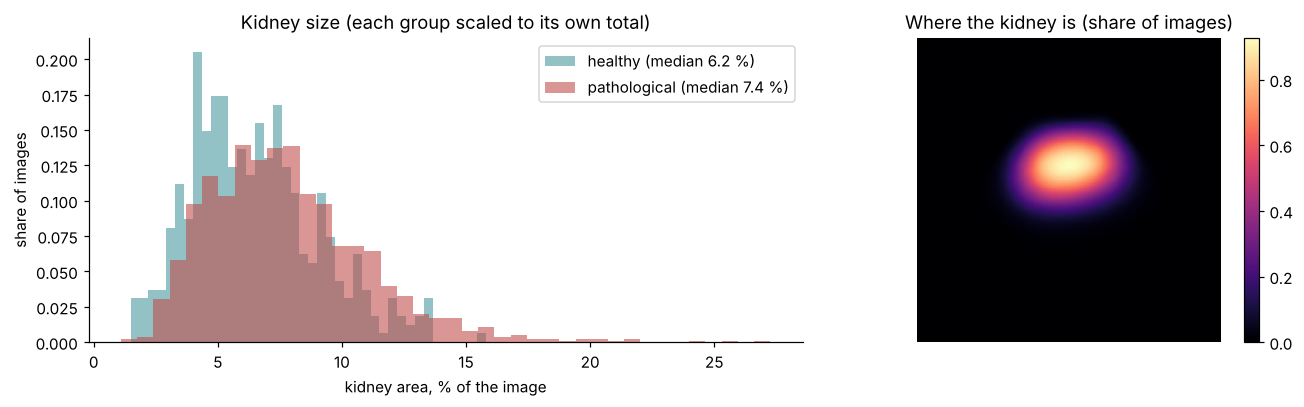

In [8]:
lab_idx = labels_a.set_index("image_id")
chk["diagnosis_name"] = chk.image_id.map(lab_idx.diagnosis).map({0: "healthy", 1: "pathological"})
heat_a = np.zeros((128, 128), np.float32)
for iid in labels_a.image_id:
    heat_a += resize_to(load_mask_a(iid))
heat_a /= len(labels_a)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
for name, col in [("healthy", "#4a9a9f"), ("pathological", "#c0504d")]:
    axes[0].hist(chk.loc[chk.diagnosis_name == name, "area_frac"] * 100, bins=40, alpha=.6, color=col, density=True,
                 label=f"{name} (median {chk.loc[chk.diagnosis_name == name, 'area_frac'].median() * 100:.1f} %)")
axes[0].set(xlabel="kidney area, % of the image", ylabel="share of images", title="Kidney size (each group scaled to its own total)"); axes[0].legend()
im = axes[1].imshow(heat_a, cmap="magma", vmin=0, vmax=heat_a.max()); axes[1].axis("off")
axes[1].set_title("Where the kidney is (share of images)"); plt.colorbar(im, ax=axes[1], fraction=.046)
plt.tight_layout(); plt.show()

**Figure 1.2.** The lesion boxes, by type, and whether their centre lies inside the kidney outline.

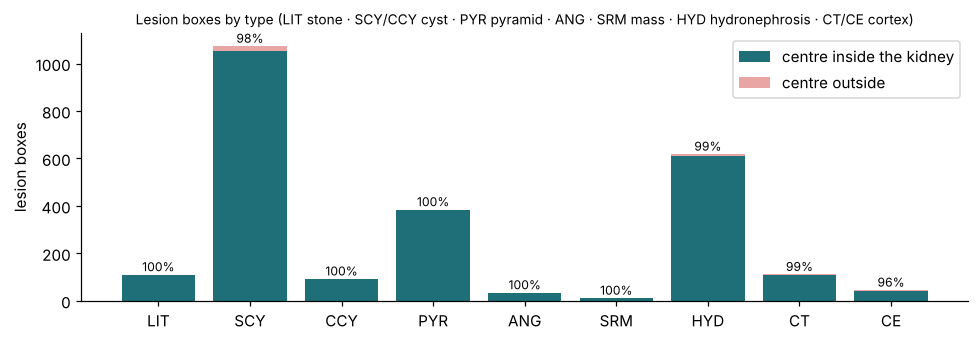

In [9]:
rows = []
for iid in labels_a.image_id[labels_a.n_boxes > 0]:
    m = load_mask_a(iid)
    for x, y, w, h, c in load_label_a(iid).boxes:
        cy, cx = min(y + h // 2, m.shape[0] - 1), min(x + w // 2, m.shape[1] - 1)
        rows.append({"type": C.BOX_CLASSES[c], "inside": bool(m[cy, cx])})
bx = pd.DataFrame(rows)
tab = bx.groupby("type").inside.agg(["size", "sum"]).rename(columns={"size": "boxes", "sum": "inside"})
tab = tab.reindex(list(C.BOX_CLASSES.values()))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(tab.index, tab.inside, color="#1f6f78", label="centre inside the kidney")
ax.bar(tab.index, tab.boxes - tab.inside, bottom=tab.inside, color="#e8a5a3", label="centre outside")
for i, (b, s) in enumerate(zip(tab.boxes, tab.inside)): ax.text(i, b + 15, f"{s / b:.0%}", ha="center", fontsize=8)
ax.set(ylabel="lesion boxes", title="Lesion boxes by type (LIT stone · SCY/CCY cyst · PYR pyramid · ANG · SRM mass · HYD hydronephrosis · CT/CE cortex)")
ax.title.set_fontsize(9); ax.legend(); plt.tight_layout(); plt.show()



The first thing the masks tell us is how small the kidney is. On a median image it covers only about 7 % of the
frame (between 5 % and 9 % for half of the images), and the rest is liver, bowel, the black background and the
scanner's on-screen text. So the model has two jobs, not one: it has to find the kidney before it can outline it.
Several of the failures we show later come from the first job, where the model outlines a neighbouring organ
instead.

The masks are also remarkably regular. Apart from 6 masks with a second small piece and 2 with a hole, every
outline in the dataset is a single solid region. That is why, after the network makes its prediction, we keep
only the largest region and fill any holes: we are not imposing a shape the doctors did not draw, just removing
mistakes that the true outlines never contain.

The lesion boxes give a reassuring result too. In 98.7 % of the 2,478 boxes, the centre of the lesion falls
inside the kidney outline. Cutting the image down to the kidney therefore throws away almost none of the
pathology, which is what the team's kidney-focused classifier relies on.

Finally, it helps to know how these outlines were drawn. According to the URI-CADS paper [24], the nephrologists
first placed an ellipse over the kidney and then adjusted a polygon around it, so the outlines are smoother than
the real kidney border. This does not make them wrong, but it shapes how we should read our results. A very high
score on dataset A partly means "matches this drawing style", and when we move to KidneyUS, where sonographers
traced the true border, some loss of overlap is expected even for a perfect model.

### 1.2 Dataset B: KidneyUS, the external test set

KidneyUS [18] comes from another hospital and several scanners. Sonographers outlined the capsule (the whole kidney), cortex, medulla and central echo complex. It has **no pathology labels**, so we use it **only to test kidney segmentation**. It is never used for training or model selection.

KidneyUS images with a capsule outline: 487


images
view        Longitudinal     349
            Transverse       133
            Other              5
kidney_type native           338
            transplant       149
quality     Fair             485
            Poor               1
            Good               1

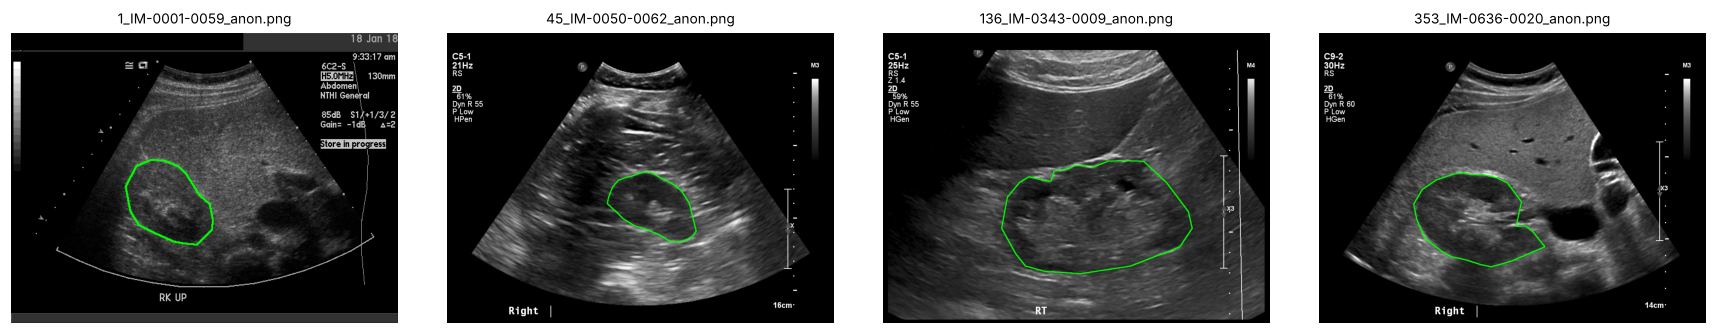

In [10]:
meta_b = list_dataset_b()        # images with a usable capsule outline (sonographer 1)
print("KidneyUS images with a capsule outline:", len(meta_b))
display(pd.concat({c: meta_b[c].value_counts() for c in ["view", "kidney_type", "quality"]}).to_frame("images"))
ims = []
for f in meta_b.filename.iloc[[0, 40, 120, 300]]:
    ims.append(overlay(load_image_b(f), load_capsule_b(f)))
show(ims, list(meta_b.filename.iloc[[0, 40, 120, 300]]))

**Figure 1.3.** Dataset A and KidneyUS side by side. Left: kidney size. Right: where the kidney sits in KidneyUS images (compare with Figure 1.1). Differences here are differences the models have to cope with on the external test.

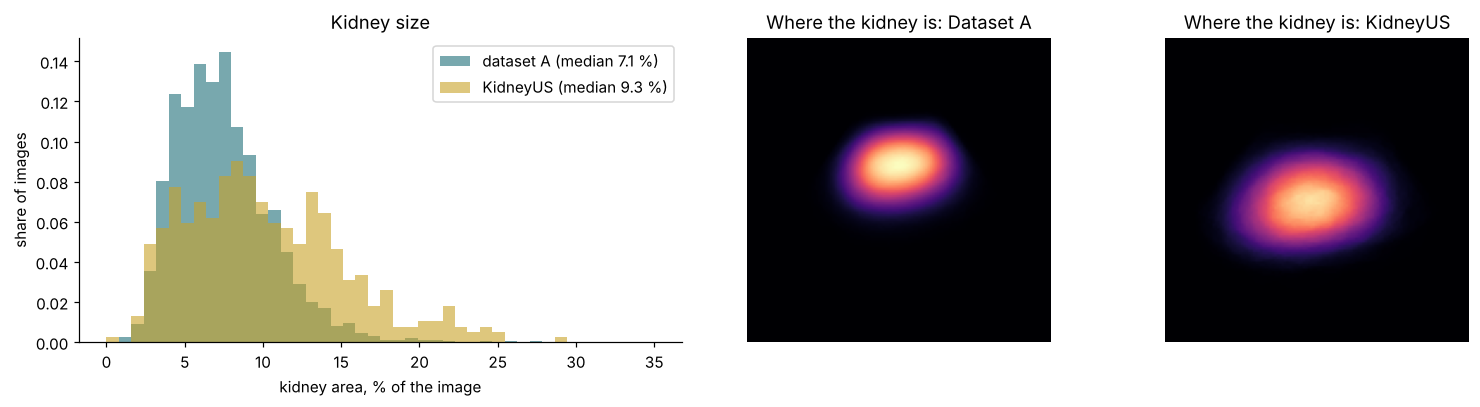

,count,area % (25th pct),area % (median),area % (75th pct)
view,,,,
Longitudinal,349.0,7.5,10.8,14.4
Other,5.0,4.0,5.7,7.0
Transverse,133.0,4.2,6.8,9.2


In [11]:
meta_b["area_frac"] = [load_capsule_b(f).mean() for f in meta_b.filename]
heat_b = np.zeros((128, 128), np.float32)
for f in meta_b.filename:
    heat_b += resize_to(load_capsule_b(f))
heat_b /= len(meta_b)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
bins = np.linspace(0, 35, 45)
axes[0].hist(chk.area_frac * 100, bins=bins, density=True, alpha=.6, color="#1f6f78",
             label=f"dataset A (median {chk.area_frac.median() * 100:.1f} %)")
axes[0].hist(meta_b.area_frac * 100, bins=bins, density=True, alpha=.6, color="#c9a227",
             label=f"KidneyUS (median {meta_b.area_frac.median() * 100:.1f} %)")
axes[0].set(xlabel="kidney area, % of the image", ylabel="share of images", title="Kidney size"); axes[0].legend()
for ax, h, t in [(axes[1], heat_a, "Dataset A"), (axes[2], heat_b, "KidneyUS")]:
    ax.imshow(h, cmap="magma", vmin=0, vmax=max(heat_a.max(), heat_b.max())); ax.set_title(f"Where the kidney is: {t}"); ax.axis("off")
plt.tight_layout(); plt.show()
display(meta_b.groupby("view").area_frac.describe()[["count", "25%", "50%", "75%"]].mul([1, 100, 100, 100]).round(1)
        .rename(columns={"25%": "area % (25th pct)", "50%": "area % (median)", "75%": "area % (75th pct)"}))

The two datasets differ in three ways that a model has to survive: **scanner** (one Toshiba vs several), **view** (dataset A is 93 % one view; KidneyUS is mostly longitudinal) and **outline style** (smooth ellipse-like vs real border). Transplant kidneys appear only in KidneyUS.

## 2. Protocol

### 2.1 Split
We follow the URI-CADS protocol [24]: **5-fold cross-validation**, and in each repetition 3 folds train, 1 validates and 1 tests. Every image is tested exactly once, by a model that never saw it.

**Which fold file.** We did not make our own split. `kidney.splits` copies the team's EDA split, **`results/eda/folds.csv`** (group-aware `StratifiedGroupKFold` [S25], near-duplicate images kept in one fold), to `results/splits/folds.csv`. The cell below checks, image by image, that the two files assign every image to the same fold.

In [12]:
folds = read_folds()
team = pd.read_csv(C.TEAM_FOLDS_CSV)                         # results/eda/folds.csv (team EDA split)
team["image_id"] = team.filename.str.replace(".jpg", "", regex=False)
same = folds.merge(team[["image_id", "fold"]], on="image_id", suffixes=("_ours", "_team"))
print(f"Same fold as the team EDA file {C.TEAM_FOLDS_CSV.relative_to(C.ROOT)}: "
      f"{(same.fold_ours == same.fold_team).mean():.0%} of {len(same)} images")
corrected = C.RESULTS / "eda" / "folds_corrected.csv"
if corrected.exists():
    cor = pd.read_csv(corrected); cor["image_id"] = cor.filename.str.replace(".jpg", "", regex=False)
    m = folds.merge(cor[["image_id", "fold"]], on="image_id", suffixes=("_ours", "_corrected"))
    print(f"Same fold as folds_corrected.csv: {(m.fold_ours == m.fold_corrected).mean():.0%}")
else:
    print("folds_corrected.csv is not on this branch (it is on main, see the note below).")
tab = folds.groupby("fold").agg(images=("image_id", "size"), pathological_share=("diagnosis", "mean"))
tab["pathological_share"] = (100 * tab.pathological_share).round(1)
display(tab)
print("Groups split across folds:", int((folds.groupby("group_id").fold.nunique() > 1).sum()))
display(pd.DataFrame([fold_roles(k) for k in range(5)], index=[f"repetition {k}" for k in range(5)]))

Same fold as the team EDA file results/eda/folds.csv: 100% of 1985 images
folds_corrected.csv is not on this branch (it is on main, see the note below).


,images,pathological_share
fold,,
0,397,77.3
1,397,77.3
2,396,77.3
3,396,77.3
4,399,77.4


Groups split across folds: 0


,test,val,train
repetition 0,0,1,"[2, 3, 4]"
repetition 1,1,2,"[0, 3, 4]"
repetition 2,2,3,"[0, 1, 4]"
repetition 3,3,4,"[0, 1, 2]"
repetition 4,4,0,"[1, 2, 3]"


**Figure 2.1.** What each fold contains. A fair comparison needs every fold to look alike: the same share of pathological kidneys, of the two hard global findings (PCD, HC) and of the rare view.

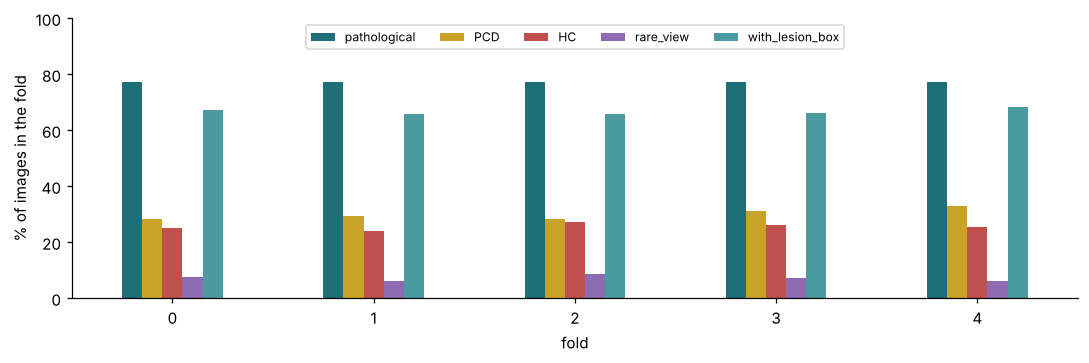

In [13]:
fa = folds.merge(labels_a, on="image_id", suffixes=("", "_lab"))
share = fa.groupby("fold").agg(pathological=("diagnosis", "mean"), PCD=("pcd", "mean"), HC=("hc", "mean"),
                               rare_view=("view", "mean"), with_lesion_box=("n_boxes", lambda s: (s > 0).mean())) * 100
ax = share.plot.bar(figsize=(10, 3.4), rot=0, color=["#1f6f78", "#c9a227", "#c0504d", "#8e6bb0", "#4a9a9f"])
ax.set(ylabel="% of images in the fold", xlabel="fold", ylim=(0, 100))
ax.legend(ncol=5, fontsize=8, loc="upper center"); plt.tight_layout(); plt.show()

**Validation fold and a correction to the split.**

In each repetition we test on one fold and use the next one to decide when to stop training: for repetition *k*,
fold *k* is the test set and fold *k*+1 the validation set (table above). The test fold is touched only once, for
the final score.

After these runs, the team found a problem in this split. Images 541 and 542 are near-copies but had been placed
in different folds. In notebook 04 on `main` they merged the two into one group and rebuilt the split, producing
`folds_corrected.csv` and `nested_cv_splits.csv`. The second file also changes how validation is chosen: instead
of taking the next fold, it sets aside part of the training folds in each repetition. The classification notebook
05 already uses these new files.

For our results this has two consequences. The scores in this notebook still stand, since the old split leaked
only that one pair. However, the predicted outlines cannot yet be passed to the classifier: the new folds are
arranged very differently (only about 20 % of images keep their old fold number), so for many images our outline
would come from a model that had seen that image during training. The fix is to retrain the segmentation models
on the corrected split, which we list as the first next step in section 9.

### 2.2 How we measure an outline

To know whether a predicted outline is good, we compare it with the outline the nephrologists drew. We look at
two questions: **how much do the two outlines overlap**, and **how far apart are their borders**.

**Overlap: Dice and IoU.** Imagine laying our outline on top of the doctor's outline.

- **Dice** counts the area the two share, doubled, and divides it by the total area of both outlines:
  Dice = 2 × shared area ÷ (our area + doctor's area).
- **IoU** (intersection over union) divides the shared area by everything covered by either outline:
  IoU = shared area ÷ combined area.

Both go from 0 (no overlap at all) to 1 (identical outlines). IoU is the stricter of the two, so the same outline
always scores lower in IoU than in Dice. We use both because they are the two scores URI-CADS reports [24], which
lets us compare with the baseline directly.

**Border distance: HD95.** Overlap alone can hide some mistakes. If the model outlines the kidney well but also
adds a small blob near the liver, the overlap barely changes, because the blob is tiny compared with the kidney.
The border, however, is now wrong in one place. **HD95** [S29] measures this: it looks at the distance between
the two borders all the way around and reports the 95th percentile, in pixels. In plain words: *apart from the
worst 5 % of points, our border is never further than this from the doctor's.* Lower is better, and 0 means the
borders coincide.

**From one image to one number.** Each score is computed for every image. To summarise a model we average them
in the same way as URI-CADS: first over the images of each test fold, then over the 5 folds, reported as
**mean ± standard deviation**. The standard deviation shows how stable the model is from one fold to the next.
We also give a **95 % confidence interval** [S27], obtained by resampling the 1,985 per-image scores many times. If
the baseline value lies outside this interval, the difference is unlikely to be due to chance.

All three scores come from the same functions in `src/kidney/metrics.py` (`dice`, `iou`, `hd95`), so every model
and every dataset is measured in exactly the same way.

**Figure 2.2. Reading a score on real predictions.** Below are four DeepLabV3+ predictions with very different scores. Each pixel is coloured by what happened: **green** = kidney that the model found, **red** = drawn by the model but not kidney, **blue** = kidney that the model missed. This is what a Dice of 0.95, 0.90, 0.80 or 0.60 looks like in practice.

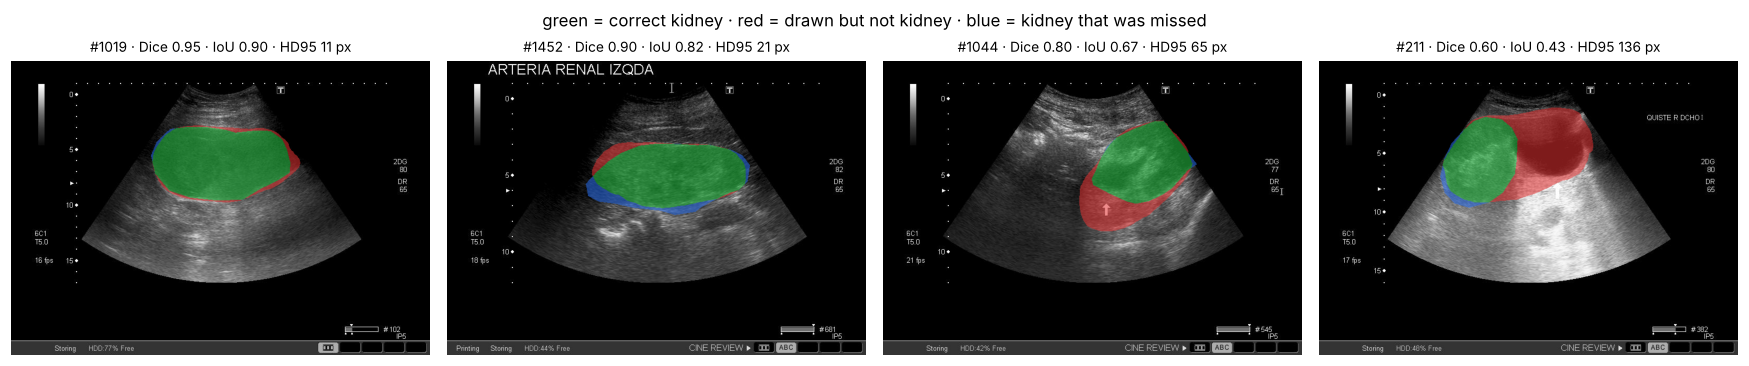

In [14]:
dl = pd.read_csv(C.SEG_DIR / "deeplabv3p_r50" / "per_image.csv", dtype={"image_id": str}).set_index("image_id")
picks = [(dl.dice - t).abs().idxmin() for t in (0.95, 0.90, 0.80, 0.60)]
ims, tts = [], []
for iid in picks:
    ims.append(error_overlay(load_image_a(iid), load_mask_a(iid), load_pred("deeplabv3p_r50", iid)))
    r = dl.loc[iid]; tts.append(f"#{iid} · Dice {r.dice:.2f} · IoU {r.iou:.2f} · HD95 {r.hd95:.0f} px")
show_rgb(ims, tts, suptitle=ERROR_LEGEND)

## 3. Method A: CNNs trained on our data

### 3.1 The two networks

Both models follow the same basic idea, an **encoder–decoder**. The encoder looks at the image at smaller and
smaller scales, learning what is in it (texture, edges, organ shapes) but losing the exact position of things.
The decoder then works its way back up to full size and decides, pixel by pixel, whether each one belongs to the
kidney. The two networks differ in how they recover the fine detail lost by the encoder.

**U-Net with a ResNet-34 encoder** [S18], [S17]. The encoder shrinks the image in five steps, halving it each time,
so a 512 × 512 input becomes a 16 × 16 map of features. The decoder enlarges it again in five steps. At each step,
it receives a copy of the encoder's features at the same size, through so-called *skip connections*. These copies
carry the sharp, local detail (where exactly the border is), while the deep layers carry the context (this dark
oval is a kidney, not the bowel). U-Net is the most used architecture for kidney ultrasound in our literature
review [12], [18], [19], [22], so it is the natural first choice.

**DeepLabV3+ with a ResNet-50 encoder** [S19]. Instead of shrinking the image all the way, DeepLabV3+ stops at
1/16 of the input size and then uses *dilated* (atrous) convolutions: filters with gaps between their weights, so
they see a wider area without reducing resolution further. A module called ASPP applies several of these filters
with different gap sizes at once, so the network sees the kidney at several scales together. That is useful
because kidney size varies a lot between images (1 % to 27 % of the frame). A light decoder then combines this
with early, high-resolution features and upsamples to full size. We include it because it is the reference model
in URI-CADS (Table 5, Dice 89.34 [24]), which lets us compare with their training directly.

**Why pretrained encoders.** Both encoders start from weights learned on ImageNet (natural photographs) [S17].
Ultrasound looks nothing like photographs, but the first layers learn general things (edges, blobs, textures)
that transfer well. With 1,985 images, starting from scratch would be much harder. Because ImageNet encoders expect
colour images, the grayscale ultrasound is copied into three identical channels and normalised with the ImageNet
mean and standard deviation.

### 3.2 From raw image to network input

1. **Letterbox to 512 × 512.** Images come in 18 different sizes, mostly 800 × 561. Simply resizing them to a
   square would squash the kidney. Instead, we first pad the shorter side with black to make a square, then
   resize to 512 × 512. After prediction we undo both steps exactly, so every score is computed at the image's
   original resolution.
2. **Intensity scaling.** Brightness and gain differ between examinations. We clip each image at its 1st and 99th
   percentile and rescale to [0, 1] (MONAI [S21]), so a few very bright or dark pixels do not dominate.
3. **Augmentation** (training images only). Each time a training image is shown, it is changed at random, and the
   same geometric change is applied to its outline:
   - with probability 0.8: rotation of up to ±15°, shift of up to ±8 % of the image side, zoom of up to ±15 %;
   - with probability 0.5: a gamma change between 0.7 and 1.5 (darker or brighter mid-tones);
   - with probability 0.2: mild Gaussian noise (SD 0.02), imitating speckle.

   The types of change follow URI-CADS (rotation, gamma, translation, zoom [24]); the ranges are ours. The goal is
   that the model learns what a kidney looks like, not the exact position and contrast of the training images.

### 3.3 Training

**Loss: Dice loss + binary cross-entropy (equal weight).** The kidney is only about 7 % of the image, so a model
that predicts "background everywhere" would already be right on 93 % of pixels. Cross-entropy alone, which scores
every pixel separately, can be slow to escape that. **Dice loss** [S24] scores the overlap with the kidney
directly, so the background cannot dominate. Cross-entropy gives smooth, stable gradients early in training,
when the overlap is still poor. Together they combine both strengths.

**Optimiser: AdamW** [S30], learning rate 3·10⁻⁴, weight decay 10⁻⁴. AdamW adapts the step size for each weight,
and applies weight decay separately from the gradient step, a mild pull of the weights towards zero that limits
overfitting.

**Learning-rate schedule: cosine annealing** over 100 epochs. The learning rate starts at 3·10⁻⁴ and decreases
smoothly along a cosine curve, so the model makes large changes early and fine adjustments later.

**Batch size 8, mixed precision.** Eight 512 × 512 images fit in the 8 GB of the laptop GPU we used. Mixed
precision (16-bit arithmetic where it is safe) roughly halves memory use and speeds up training.

**Early stopping** on the validation fold. After every epoch, we compute the Dice score on the validation fold
(at 512 px) and keep the weights of the best epoch. If 15 epochs pass without improvement, training stops; the
maximum is 100 epochs. The best epoch was 26–50 for U-Net and 45–73 for DeepLabV3+, and one fold took 24–37 min
(U-Net) and 36–54 min (DeepLabV3+) on an RTX 4060 laptop GPU. The test fold plays no part in any of this.

**Seed** 42 plus the fold index, so each run can be repeated exactly.

### 3.4 From prediction to final outline

The network outputs, for every pixel, the probability that it belongs to the kidney. We keep pixels above 0.5,
map the result back to the original image size, and then **keep only the largest connected region and fill its
holes**. Section 1 showed that almost every reference outline is one solid region, so any extra piece is an error.
In practice this step rarely matters but helps when it does: it changed the outline in 43 images for U-Net and 22
for DeepLabV3+, raised the average Dice by only 0.02 points, but lowered the average HD95 from 21.2 to 20.7 px
(U-Net). In 10 images it removed a stray piece and cut the border error by more than 20 px.

### 3.5 Parameter summary

| Parameter | Value | Why |
|---|---|---|
| Encoders | ResNet-34 (U-Net), ResNet-50 (DeepLabV3+), ImageNet weights | Transfer learning with limited data |
| Input | grayscale × 3 channels, letterbox 512 × 512, ImageNet normalisation | Keeps the kidney's shape; matches the encoders |
| Intensity | clip at 1st–99th percentile → [0, 1] | Removes gain differences between scans |
| Geometric augmentation (p = 0.8) | rotation ±15°, shift ±8 %, zoom ±15 % | Position and size vary between scans [24] |
| Intensity augmentation | gamma 0.7–1.5 (p = 0.5), Gaussian noise SD 0.02 (p = 0.2) | Contrast and speckle vary [24], [S21] |
| Loss | Dice loss + BCE, equal weight | Small target (≈ 7 % of the image) [S24] |
| Optimiser | AdamW, lr 3·10⁻⁴, weight decay 10⁻⁴ | Stable training with mild regularisation [S30] |
| Schedule | cosine annealing, 100 epochs | Large steps early, fine-tuning late |
| Batch | 8, mixed precision | Fits an 8 GB GPU |
| Stopping | best validation Dice, patience 15, max 100 epochs | Avoids overfitting; test fold untouched |
| Output | probability > 0.5, largest region, holes filled | True outlines are one solid region |
| Seed | 42 + fold index | Reproducible | |

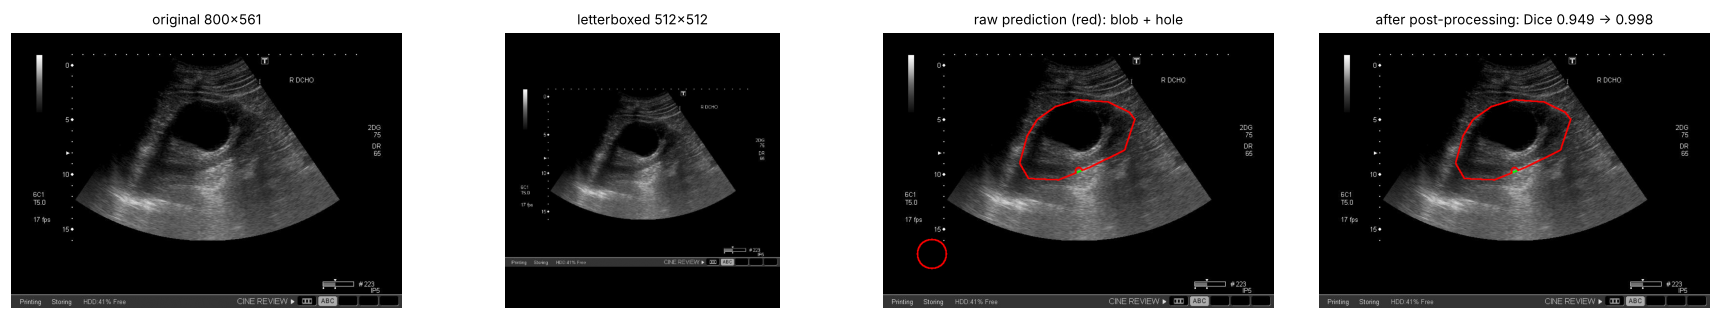

In [15]:
# Steps 1 and 6 on a real image
img, gt = load_image_a("282"), load_mask_a("282")
lb_img, lb = letterbox(img, 512)
noisy = gt.copy(); cv2.circle(noisy, (100, 450), 30, 1, -1); cv2.circle(noisy, (gt.shape[1] // 2, gt.shape[0] // 2), 6, 0, -1)
clean = postprocess(noisy)
show([img, lb_img, overlay(img, gt, pred=noisy), overlay(img, gt, pred=clean)],
     [f"original {img.shape[1]}x{img.shape[0]}", "letterboxed 512x512", "raw prediction (red): blob + hole",
      f"after post-processing: Dice {dice(noisy, gt):.3f} -> {dice(clean, gt):.3f}"])

In [16]:
# Train (only when RUN_PIPELINE=True; each fold takes 25-55 min on one GPU)
if RUN_PIPELINE:
    for m in ["unet_r34", "deeplabv3p_r50"]:
        subprocess.run([sys.executable, "-m", "kidney.train_seg", "--model", m] + ([SMK] if SMK else []), check=True)

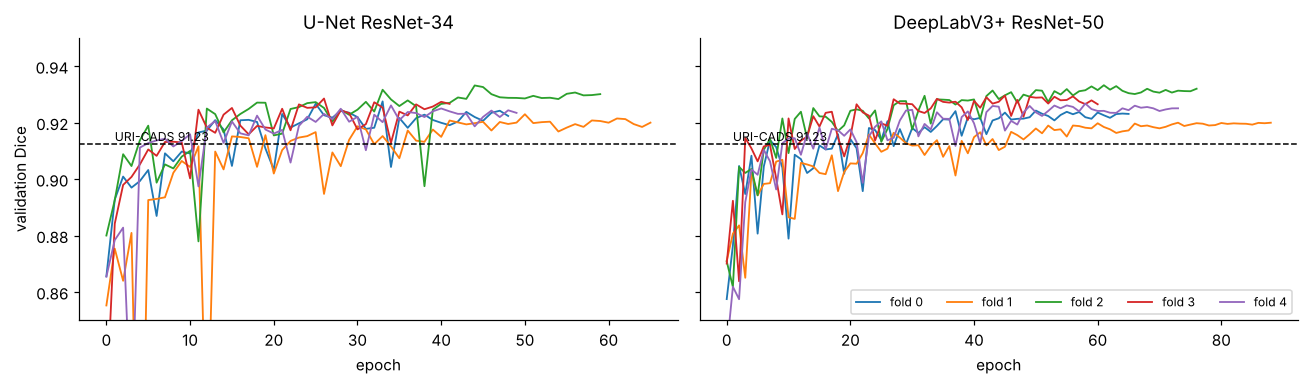

fold,0,1,2,3,4
model,,,,,
DeepLabV3+ ResNet-50,50.0,73.0,61.0,45.0,58.0
U-Net ResNet-34,33.0,50.0,44.0,26.0,34.0


In [17]:
# Training curves: validation Dice per epoch, one line per fold
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, m in zip(axes, ["unet_r34", "deeplabv3p_r50"]):
    for f in range(5):
        h = pd.read_csv(C.SEG_DIR / m / f"history_fold{f}.csv")
        ax.plot(h.epoch, h.val_dice, lw=1.2, label=f"fold {f}")
    ax.axhline(0.9123, color="k", ls="--", lw=1); ax.text(1, 0.9135, "URI-CADS 91.23", fontsize=8)
    ax.set(title=MODEL_NAMES[m], xlabel="epoch", ylim=(0.85, 0.95))
axes[0].set_ylabel("validation Dice"); axes[1].legend(fontsize=8, ncol=5, loc="lower right")
plt.tight_layout(); plt.show()

runs = pd.read_csv(C.RUNS_CSV)
runs = runs[(runs.phase == "seg") & runs.model.isin(["unet_r34", "deeplabv3p_r50"]) & ~runs.smoke]
display(runs.pivot_table(index="model", columns="fold", values="best_epoch").rename(index=MODEL_NAMES))

Both networks reach the URI-CADS level within the first 10–20 epochs and then improve slowly. Early stopping picks the best epoch per fold (table), so we do not use an overfitted final epoch.

**Figure 3.1.** Training loss per epoch (all folds). The loss keeps falling while the validation Dice (above) levels off: the point where they part is where early stopping becomes useful.

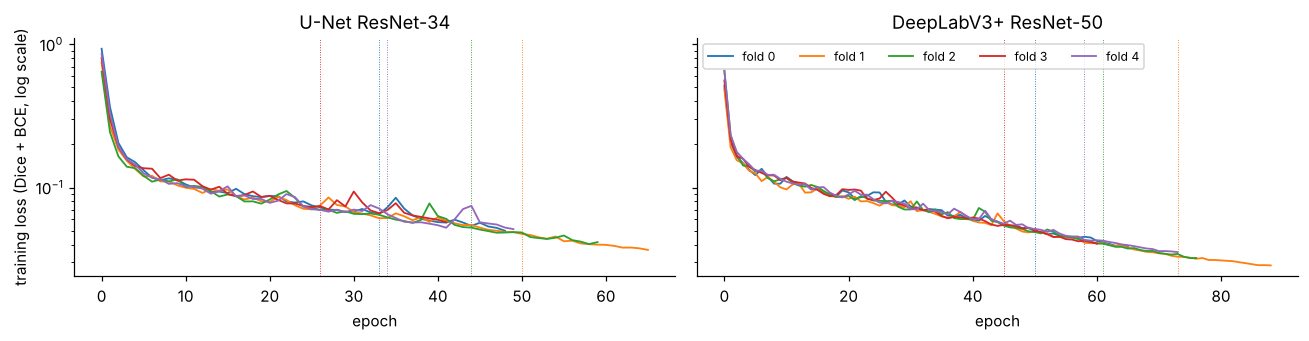

Dotted lines: the epoch kept by early stopping in each fold.


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, m in zip(axes, ["unet_r34", "deeplabv3p_r50"]):
    for f in range(5):
        h = pd.read_csv(C.SEG_DIR / m / f"history_fold{f}.csv")
        ax.plot(h.epoch, h.train_loss, lw=1.2, label=f"fold {f}")
        be = runs[(runs.model == m) & (runs.fold == f)].best_epoch.iloc[0]
        ax.axvline(be, color=ax.lines[-1].get_color(), lw=.6, ls=":")
    ax.set(title=MODEL_NAMES[m], xlabel="epoch", yscale="log")
axes[0].set_ylabel("training loss (Dice + BCE, log scale)"); axes[1].legend(fontsize=8, ncol=5)
plt.tight_layout(); plt.show()
print("Dotted lines: the epoch kept by early stopping in each fold.")

**Figure 3.2. U-Net and DeepLabV3+ on the same images.** Four typical images (around the median score), predicted by each network. Colours as in Figure 2.2.

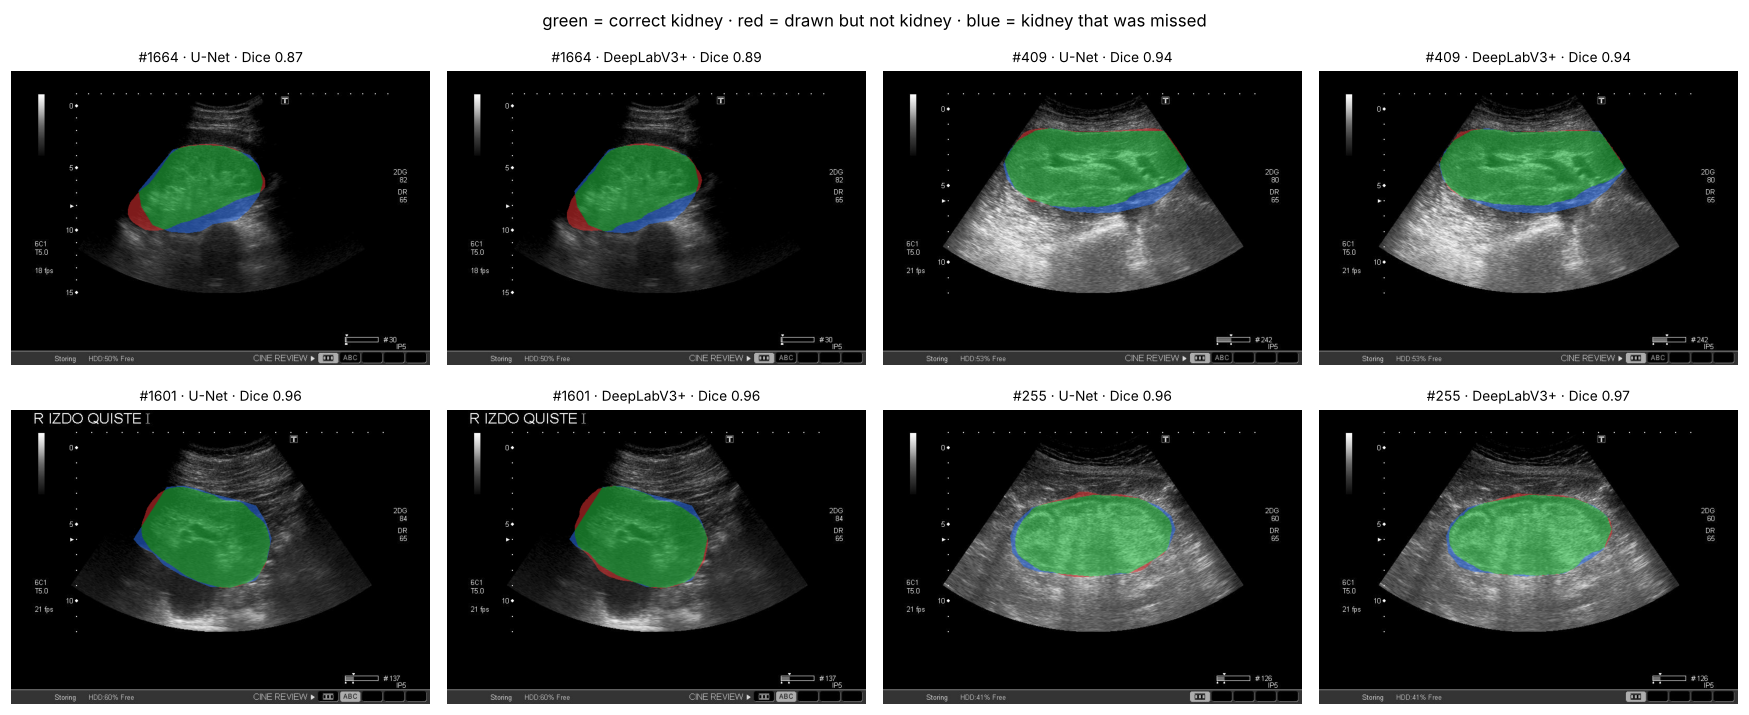

In [19]:
un = pd.read_csv(C.SEG_DIR / "unet_r34" / "per_image.csv", dtype={"image_id": str}).set_index("image_id")
mid = dl.dice.sort_values().index[[400, 900, 1300, 1700]]
ims, tts = [], []
for iid in mid:
    img, gt = load_image_a(iid), load_mask_a(iid)
    for m, s in [("unet_r34", un), ("deeplabv3p_r50", dl)]:
        ims.append(error_overlay(img, gt, load_pred(m, iid)))
        tts.append(f"#{iid} · {MODEL_NAMES[m].split(' ')[0]} · Dice {s.dice[iid]:.2f}")
show_rgb(ims, tts, ncols=4, suptitle=ERROR_LEGEND)

**Table 3.1. What the final clean-up (largest region + holes filled) changed.** The pipeline stores the score before (`raw`) and after the clean-up for every image.

In [20]:
rows = []
for m, s in [("unet_r34", un), ("deeplabv3p_r50", dl)]:
    changed = s[(s.dice != s.dice_raw) | (s.hd95 != s.hd95_raw)]
    rows.append({"model": MODEL_NAMES[m], "images changed": len(changed),
                 "mean Dice before → after": f"{s.dice_raw.mean() * 100:.2f} → {s.dice.mean() * 100:.2f}",
                 "mean HD95 before → after (px)": f"{s.hd95_raw.mean():.1f} → {s.hd95.mean():.1f}",
                 "images where HD95 fell by > 20 px": int(((s.hd95_raw - s.hd95) > 20).sum())})
pd.DataFrame(rows).set_index("model")

,images changed,mean Dice before → after,mean HD95 before → after (px),images where HD95 fell by > 20 px
model,,,,
U-Net ResNet-34,43,92.18 → 92.20,21.2 → 20.7,10
DeepLabV3+ ResNet-50,22,92.33 → 92.35,20.3 → 20.0,5


## 4. Method B: foundation models with a box prompt

### 4.1 The idea

The networks in section 3 learn the kidney from our 1,985 images. **Foundation models** take the opposite route:
they are trained once, on a very large and varied collection of images and outlines, to outline *whatever object
you point at*. You do not train them on your task. You give them an image and a **prompt**, here a box drawn
around the kidney, and they return the outline of the object inside the box.

The question for us is simple: **can such a model, never trained on our data, outline the kidney as well as our
trained CNNs?** If it can, it could also outline structures we have no training masks for, such as the lesions
inside the kidney .

### 4.2 How a segment-anything model works

Both models we test share the architecture of SAM (Segment Anything), in its ViT-B size, and have three parts:

1. **Image encoder.** A Vision Transformer (ViT-B) [S16] cuts the image into small patches and turns it into a
   grid of features describing what is where. This is the large, slow part, and it runs once per image.
2. **Prompt encoder.** It turns the box (its two corners) into a small set of numbers the model can use.
3. **Mask decoder.** A small network combines the image features with the box and produces a probability map of
   the object, at 256 × 256, which is then enlarged to the original image size.

We ask for a single outline per box (`multimask_output=False`), keep pixels with probability above 0.5, and apply
the same clean-up as for the CNNs: keep the largest region and fill holes (section 3.4).

### 4.3 The two models

| | **MedSAM** [S3] | **UltraSam** [S1] |
|---|---|---|
| Trained on | about 1.5 million medical image–outline pairs, many modalities (CT, MRI, X-ray, ultrasound, …) | US-43d, a collection of 43 open ultrasound datasets |
| Strength | broad medical knowledge | specialised in ultrasound appearance (speckle, shadows, fan shape) |
| Weights | `medsam_vit_b.pth` (Zenodo 10689643) | `UltraSam.pth` (CAMMA-public GitHub) |
| How we load it | directly with `segment_anything` | converted from its MMDetection format to the SAM layout (`load_ultrasam`) |

UltraSam is released in a different format from SAM. Our loader translates its weight names to the SAM ones and
**refuses to run if fewer than 95 % of SAM's weights are found**, so a wrong conversion cannot quietly produce
numbers. A unit test (`tests/test_ultrasam_mapping.py`) checks this mapping.

### 4.4 Preprocessing

Each model gets the preprocessing it was trained with, as its authors describe:

- **MedSAM** (official recipe, `MedSAM_Inference.py` [S3]): the grayscale image is copied to three channels,
  resized to 1024 × 1024 and rescaled to [0, 1] using its own minimum and maximum. The box is scaled the same way.
- **UltraSam** (standard SAM, through `SamPredictor`): the longest side is resized to 1024 and the rest is padded,
  then pixels are normalised with SAM's mean and standard deviation.

There is no augmentation, because there is no training.

### 4.5 Where the box comes from

The box is everything these models know about the kidney's location, so we test two sources:

- **True box (`gt`)**: the tightest box around the nephrologists' outline. This is not possible for a new
  patient, since nobody has drawn the outline yet. It tells us the **best the model can do** when the box is
  perfect, so it is an **upper bound**.
- **Automatic box (`auto`)**: the tightest box around the outline predicted by our U-Net (section 3). This is the
  **fully automatic** pipeline that could run on a new image. Because we use the U-Net's *out-of-fold*
  predictions, each image's box comes from a U-Net that never saw that image, so there is no leak. The U-Net found
  a kidney in every image, so no automatic box was missing.

No margin is added around either box. Even though the models are not trained, we still report their scores fold
by fold, using the same 5 folds as the CNNs, so all results line up.

### 4.6 Parameter summary

| Parameter | MedSAM | UltraSam |
|---|---|---|
| Architecture | SAM ViT-B: image encoder, prompt encoder, mask decoder | same |
| Weights | `medsam_vit_b.pth`, Zenodo 10689643 [S3] | `UltraSam.pth`, CAMMA-public [S1]; loaded only if ≥ 95 % of weights match |
| Training on our data | none | none |
| Input | gray × 3 channels, resized to 1024 × 1024, min–max to [0, 1] | gray × 3 channels, longest side 1024 + padding, SAM mean/std |
| Prompt | one box (x0, y0, x1, y1), no margin | same |
| True box | tight box of the reference outline (upper bound) | same |
| Automatic box | tight box of the U-Net out-of-fold outline | same |
| Outputs per box | one (`multimask_output=False`) | same |
| Output | probability > 0.5, back to original size, largest region + holes filled | same ||

### 4.7 How good is the automatic box?

Since the foundation models depend entirely on the box, the first thing to check is how close the automatic box
is to the true one. The cell below compares them with the box IoU (shared area ÷ combined area of the two boxes),
and shows how each model's score changes with box quality.

In [21]:
if RUN_PIPELINE:
    if not SMOKE: subprocess.run(["bash", "scripts/download_weights.sh"], check=True)
    for m in ["medsam", "ultrasam"]:
        subprocess.run([sys.executable, "-m", "kidney.sam_prompt", "--model", m] + ([SMK] if SMK else []), check=True)

Automatic box vs true box: median IoU 0.897; 48% of images have IoU >= 0.90


,images,MedSAM_auto,MedSAM_true_box,UltraSam_auto,UltraSam_true_box
box_quality,,,,,
< 0.70,162,0.716,0.874,0.735,0.919
0.70-0.80,196,0.829,0.882,0.856,0.927
0.80-0.90,668,0.880,0.899,0.907,0.931
>= 0.90,959,0.910,0.914,0.935,0.940


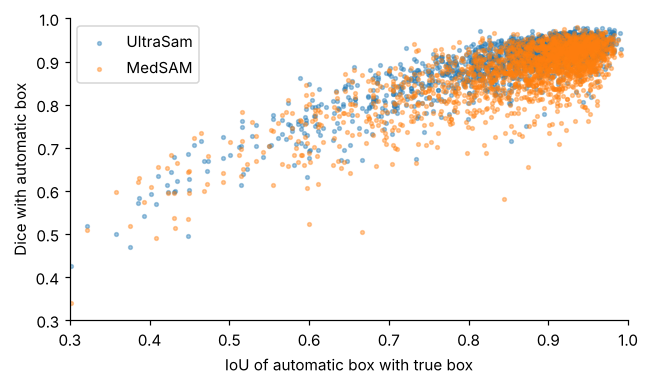

In [22]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy; ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

kb = pd.read_csv(C.RESULTS / "kidney_boxes.csv", dtype={"image_id": str})
kb["box_iou"] = [box_iou((r.x0, r.y0, r.x1, r.y1), (r.gt_x0, r.gt_y0, r.gt_x1, r.gt_y1)) for r in kb.itertuples()]
sam = {m: pd.read_csv(C.SEG_DIR / m / "per_image.csv", dtype={"image_id": str}).set_index("image_id").dice
       for m in ["medsam_auto", "ultrasam_auto", "medsam_gt", "ultrasam_gt"]}
kb = kb.join(pd.DataFrame(sam), on="image_id")
kb["box_quality"] = pd.cut(kb.box_iou, [0, .7, .8, .9, 1.0], labels=["< 0.70", "0.70-0.80", "0.80-0.90", ">= 0.90"])
tab = kb.groupby("box_quality", observed=True).agg(
    images=("image_id", "size"), MedSAM_auto=("medsam_auto", "mean"), MedSAM_true_box=("medsam_gt", "mean"),
    UltraSam_auto=("ultrasam_auto", "mean"), UltraSam_true_box=("ultrasam_gt", "mean"))
print(f"Automatic box vs true box: median IoU {kb.box_iou.median():.3f}; "
      f"{(kb.box_iou >= .9).mean():.0%} of images have IoU >= 0.90")
display(tab.round(3))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(kb.box_iou, kb.ultrasam_auto, s=6, alpha=.4, label="UltraSam")
ax.scatter(kb.box_iou, kb.medsam_auto, s=6, alpha=.4, label="MedSAM")
ax.set(xlabel="IoU of automatic box with true box", ylabel="Dice with automatic box", xlim=(0.3, 1), ylim=(0.3, 1))
ax.legend(); plt.tight_layout(); plt.show()

**Finding.** Foundation models are only as good as their box. With a box that overlaps the true one well, both are close to their true-box upper bound. When the box is off, Dice drops roughly in proportion. So the weak point of the automatic SAM pipeline is the box, not the outlining.

**Figure 4.1. True box versus automatic box.** For one image with a good automatic box and one with a poor one, the outline drawn by MedSAM and UltraSam from each box. **White** = true box, **yellow** = automatic box (from the U-Net). Colours inside as in Figure 2.2.

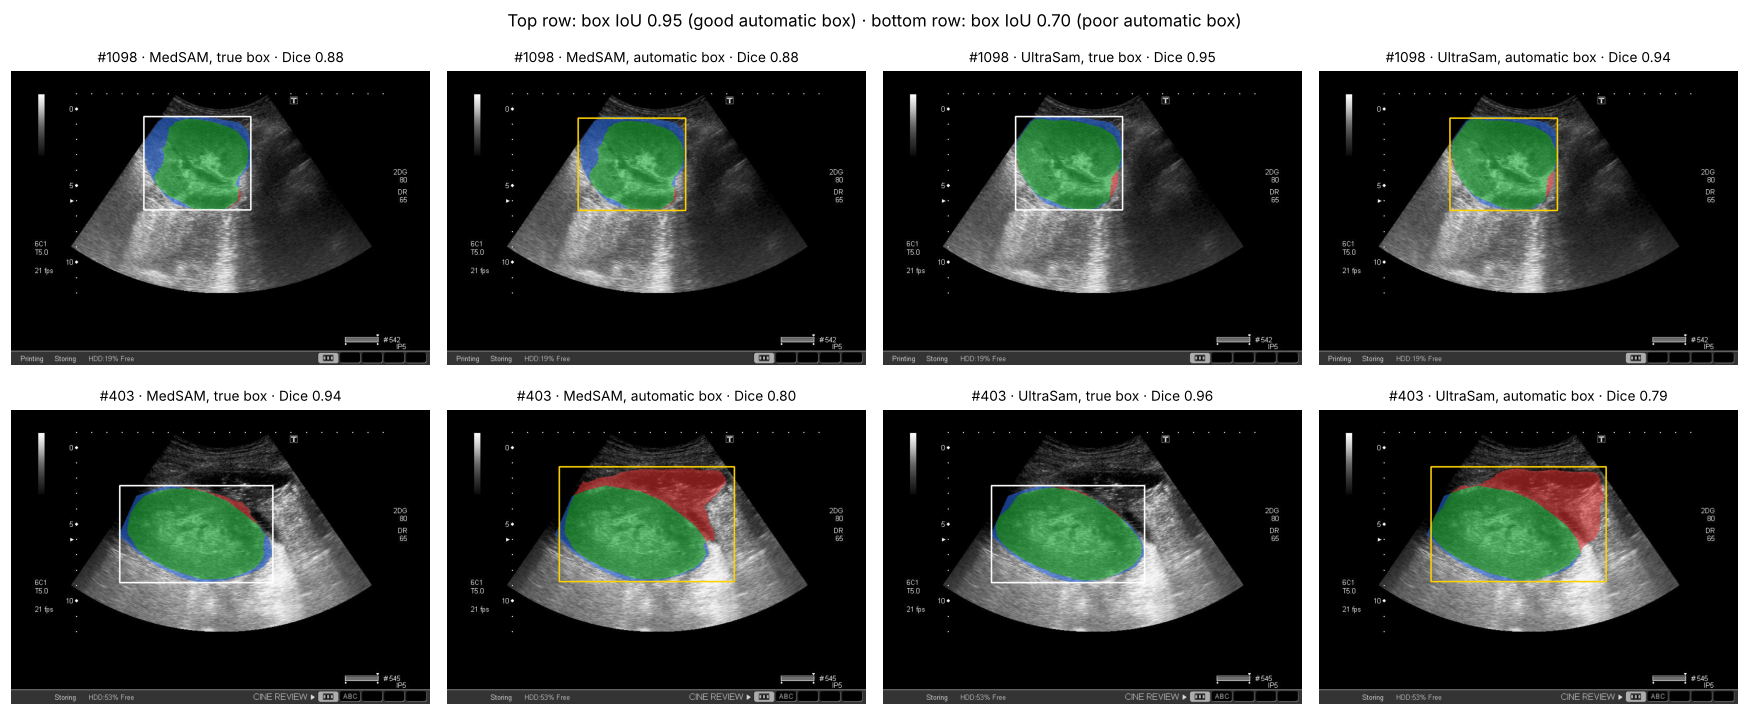

In [23]:
kbi = kb.set_index("image_id")
good = kbi[(kbi.box_iou > 0.95)].sort_values("ultrasam_gt").index[len(kbi[kbi.box_iou > 0.95]) // 2]
poor = kbi[(kbi.box_iou.between(0.55, 0.70))].sort_values("ultrasam_gt").index[-5]
ims, tts = [], []
for iid in [good, poor]:
    img, gt = load_image_a(iid), load_mask_a(iid)
    r = kbi.loc[iid]; tb, ab = (r.gt_x0, r.gt_y0, r.gt_x1, r.gt_y1), (r.x0, r.y0, r.x1, r.y1)
    for m, b in [("medsam_gt", tb), ("medsam_auto", ab), ("ultrasam_gt", tb), ("ultrasam_auto", ab)]:
        ims.append(error_overlay(img, gt, load_pred(m, iid), box=tb if m.endswith("gt") else None,
                                 box2=ab if m.endswith("auto") else None))
        tts.append(f"#{iid} · {MODEL_NAMES[m]} · Dice {r[m]:.2f}")
show_rgb(ims, tts, ncols=4, suptitle=f"Top row: box IoU {kbi.box_iou[good]:.2f} (good automatic box) · "
                                     f"bottom row: box IoU {kbi.box_iou[poor]:.2f} (poor automatic box)")

**Figure 4.2.** How much each model loses when the box comes from the U-Net instead of the reference (mean Dice over all 1,985 images).

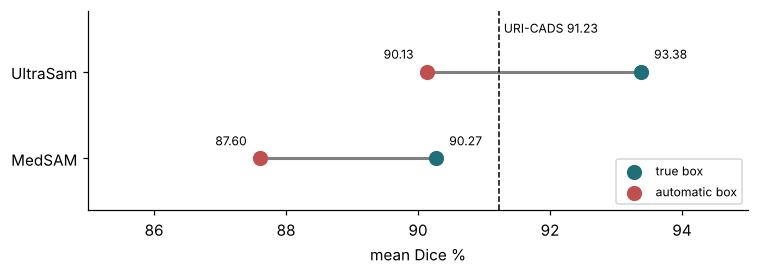

In [24]:
pairs = [("MedSAM", "medsam_gt", "medsam_auto"), ("UltraSam", "ultrasam_gt", "ultrasam_auto")]
fig, ax = plt.subplots(figsize=(7, 2.6))
for y, (n, g, a) in enumerate(pairs):
    vg, va = kb[g].mean() * 100, kb[a].mean() * 100
    ax.plot([va, vg], [y, y], color="grey", lw=2, zorder=1)
    ax.scatter([vg], [y], s=80, color="#1f6f78", zorder=2, label="true box" if y == 0 else None)
    ax.scatter([va], [y], s=80, color="#c0504d", zorder=2, label="automatic box" if y == 0 else None)
    ax.text(vg + .2, y + .15, f"{vg:.2f}", fontsize=8); ax.text(va - .2, y + .15, f"{va:.2f}", fontsize=8, ha="right")
ax.axvline(91.23, color="k", ls="--", lw=1); ax.text(91.3, 1.45, "URI-CADS 91.23", fontsize=8)
ax.set(yticks=range(len(pairs)), yticklabels=[p[0] for p in pairs], xlabel="mean Dice %", ylim=(-.6, 1.7), xlim=(85, 95))
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

## 5. Method C: fine-tuning the MedSAM decoder

### 5.1 Why fine-tune

Section 4 uses MedSAM exactly as released. MedSAM has seen many medical images, but two things are new to it in our
data: the look of **kidney ultrasound from this Toshiba scanner**, and the **outline style** of dataset A, the
smooth, ellipse-like polygons drawn by the nephrologists (section 1.1). A model that traces the true, irregular
kidney border is "wrong" by the standard of these reference outlines, even when it is anatomically right.

Retraining the whole model would take a lot of time and memory, and with 1,985 images it could easily overfit.
Instead, we follow the approach of the MedSAM authors [S3]: **keep the large parts frozen and retrain only the
small part that draws the outline**.

### 5.2 What is trained and what is frozen

Recall the three parts of a segment-anything model (section 4.2):

| Part | Role | Here |
|---|---|---|
| Image encoder (ViT-B) | turns the image into features | **frozen**: keeps MedSAM's general medical knowledge |
| Prompt encoder | turns the box into numbers | **frozen** |
| Mask decoder | combines both and draws the outline | **trained** on our data |

Because the image encoder does not change, the features of each image are the same in every epoch. We compute
them **once per image** and store them on disk (about 2 MB per image, in `results/cache/medsam_emb/`, not committed
to Git). After that, each training step only runs the small decoder. That is why the first fold takes about
17 min, most of it spent computing the stored features, and the other folds only 6–9 min.

### 5.3 Training

**Data and folds.** Each repetition uses exactly the same 3 training / 1 validation / 1 test folds as the CNNs
(section 2), through the same `split_ids` function. The decoder tested on fold *k* was trained only on the other
folds, so no test image is ever seen in training.

**Prompt during training: a slightly wrong box on purpose.** For each training image we take the true box and move
each of its four sides independently by a random amount between −20 and +20 pixels (on MedSAM's 1024 × 1024
scale, about ±16 px horizontally and ±11 px vertically on a typical 800 × 561 image). The box can therefore end
up a bit too large, too small or off-centre. This is the only augmentation, and it serves one purpose: the
automatic box from the U-Net is never perfect, so the decoder should learn to outline the kidney even when the box
is slightly off.

**What the decoder is compared with.** The decoder produces a 256 × 256 map. The reference outline is shrunk to
256 × 256 (nearest neighbour, so it stays black and white), and the two are compared there.

**Loss: Dice loss + binary cross-entropy**, equal weight, as for the CNNs (section 3.3) and as in the MedSAM recipe
[S3]. The losses of the 8 images in a batch are averaged before each update.

**Optimiser: AdamW** [S30], learning rate 10⁻⁴ (three times lower than for the CNNs, because we are adjusting an
already trained decoder, not learning from scratch), weight decay 0.01, constant learning rate, no schedule.

**Early stopping.** After every epoch, the decoder outlines each validation image from its **true** box (without
the random shift), at the original image size, and we compute the Dice score. We keep the best epoch and stop
after 6 epochs without improvement, with at most 30 epochs. The best epoch was 5–14, and validation Dice reached
about 0.95 in every fold: the decoder adapts very quickly.

**Seed** 42 plus the fold index for both PyTorch and the box shifts.

### 5.4 Testing

The fine-tuned decoder of repetition *k* outlines the images of test fold *k* twice, with the same two boxes as in
section 4:

- **`medsam_ft_gt`**: the true box (upper bound);
- **`medsam_ft_auto`**: the box around the U-Net out-of-fold outline (fully automatic).

As before, pixels with probability above 0.5 are kept, the map is enlarged to the original image size, and the
largest region is kept with its holes filled.

### 5.5 Parameter summary

**Model**

| Setting | Value |
|---|---|
| Starting point | MedSAM ViT-B weights (`medsam_vit_b.pth`) [S3] |
| Part that is trained | mask decoder only |
| Parts that stay fixed | image encoder and prompt encoder |

**Input**

| Setting | Value |
|---|---|
| Image | grayscale copied to 3 channels, resized to 1024 × 1024, scaled to [0, 1] |
| Box during training | true box, each side moved at random by up to 20 px |
| Reference outline | resized to 256 × 256, the size of the decoder output |

**Training**

| Setting | Value |
|---|---|
| Loss | Dice loss + binary cross-entropy, equal weight |
| Optimiser | AdamW |
| Learning rate | 0.0001, constant |
| Weight decay | 0.01 |
| Batch size | 8 images |
| Augmentation | none, apart from the moved box |
| Seed | 42 + fold number |

**When training stops**

| Setting | Value |
|---|---|
| Checked on | validation fold, true box, original image size |
| Rule | stop after 6 epochs with no better validation Dice |
| Maximum | 30 epochs |
| Epoch kept | the best one (between epoch 5 and 14, depending on the fold) |

**Testing**

| Setting | Value |
|---|---|
| Folds | same 3 train / 1 validation / 1 test as all other methods |
| Boxes | true box (upper bound) and U-Net box (fully automatic) |
| Final outline | probability > 0.5, original size, largest region kept, holes filled |
| Time | about 17 min for the first fold, 6–9 min for each of the others (RTX 4060 laptop) |

In [25]:
if RUN_PIPELINE:
    subprocess.run([sys.executable, "-m", "kidney.finetune_medsam"] + ([SMK] if SMK else []), check=True)
    subprocess.run([sys.executable, "-m", "kidney.report_seg"], check=True)   # tables, kidney_boxes.csv, failure overlays

**Figure 5.1. What fine-tuning changed.** Each dot is one image, with the same automatic box before (x) and after (y) fine-tuning the decoder. Dots above the diagonal improved. The table counts how many images improved, and by how much.

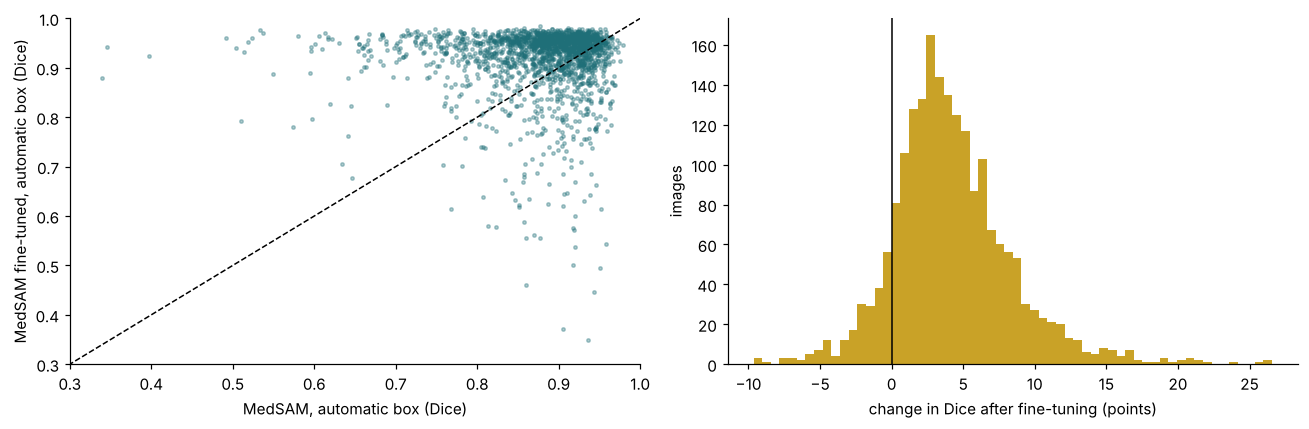

,count
images improved,1765.0
images worse,220.0
improved by more than 5 points,710.0
worse by more than 5 points,22.0
median change (points),3.7


In [26]:
ms = pd.read_csv(C.SEG_DIR / "medsam_auto" / "per_image.csv", dtype={"image_id": str}).set_index("image_id").dice
ft = pd.read_csv(C.SEG_DIR / "medsam_ft_auto" / "per_image.csv", dtype={"image_id": str}).set_index("image_id").dice
diff = (ft - ms).dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ms, ft, s=5, alpha=.35, color="#1f6f78"); axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlim=(.3, 1), ylim=(.3, 1), xlabel="MedSAM, automatic box (Dice)", ylabel="MedSAM fine-tuned, automatic box (Dice)")
axes[1].hist(diff * 100, bins=60, color="#c9a227"); axes[1].axvline(0, color="k", lw=1)
axes[1].set(xlabel="change in Dice after fine-tuning (points)", ylabel="images")
plt.tight_layout(); plt.show()
display(pd.Series({"images improved": int((diff > 0).sum()), "images worse": int((diff < 0).sum()),
                   "improved by more than 5 points": int((diff > .05).sum()),
                   "worse by more than 5 points": int((diff < -.05).sum()),
                   "median change (points)": round(float(diff.median() * 100), 2)}).to_frame("count"))

**Figure 5.2.** The four images where fine-tuning helped most: MedSAM before (left) and after (right), same automatic box. Plain MedSAM outlines only part of the kidney, usually a darker region inside it (large blue areas), while the fine-tuned decoder covers the whole kidney the way the doctors drew it.

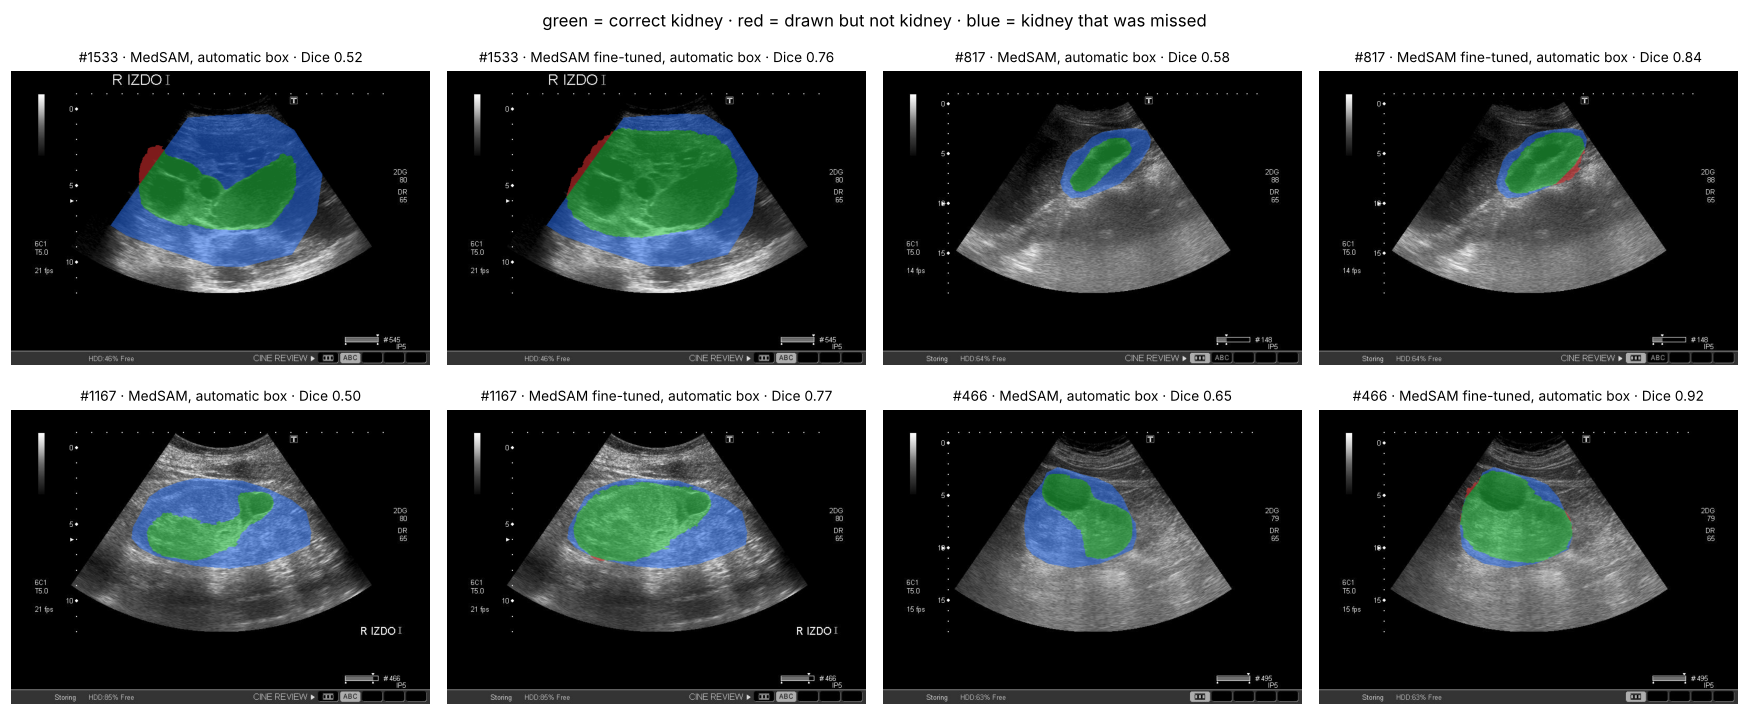

In [27]:
ims, tts = [], []
for iid in diff.sort_values().index[-4:]:
    img, gt = load_image_a(iid), load_mask_a(iid)
    for m, s in [("medsam_auto", ms), ("medsam_ft_auto", ft)]:
        ims.append(error_overlay(img, gt, load_pred(m, iid))); tts.append(f"#{iid} · {MODEL_NAMES[m]} · Dice {s[iid]:.2f}")
show_rgb(ims, tts, ncols=4, suptitle=ERROR_LEGEND)

## 6. Results on dataset A

`results_table()` (in `src/kidney/report_seg.py`) reads the out-of-fold per-image scores of every model, takes the mean ± SD of the 5 fold means and a bootstrap 95 % CI, and compares with URI-CADS [24].

In [28]:
tbl = results_table()
tbl["model"] = tbl.model.replace(MODEL_NAMES)
tbl

,model,dice,iou,hd95,dice_ci,vs_24,n_folds,n_images
0,URI-CADS-Segmentation [24],91.23,84.99,n.r.,,baseline,NaN,NaN
1,DeepLabV3+ in [24],89.34,81.80,n.r.,,,NaN,NaN
2,DeepLabV3+ ResNet-50,92.35 ± 0.48,86.39 ± 0.64,20.0 ± 1.1,"[92.07, 92.63]",beats (+1.12),5.0,1985.0
3,"MedSAM, automatic box",87.60 ± 0.35,78.63 ± 0.49,27.9 ± 0.7,"[87.28, 87.93]",below (-3.63),5.0,1985.0
4,"MedSAM fine-tuned, automatic box",91.79 ± 0.40,85.47 ± 0.59,20.7 ± 1.2,"[91.49, 92.07]",beats (+0.56),5.0,1985.0
5,"MedSAM fine-tuned, true box",95.01 ± 0.08,90.57 ± 0.14,11.8 ± 0.2,"[94.92, 95.10]",beats (+3.78),5.0,1985.0
6,"MedSAM, true box",90.27 ± 0.12,82.51 ± 0.18,20.9 ± 0.2,"[90.10, 90.44]",below (-0.96),5.0,1985.0
7,"UltraSam, automatic box",90.13 ± 0.42,82.64 ± 0.62,23.0 ± 1.1,"[89.83, 90.44]",below (-1.10),5.0,1985.0
8,"UltraSam, true box",93.38 ± 0.14,87.68 ± 0.24,14.6 ± 0.4,"[93.27, 93.49]",beats (+2.15),5.0,1985.0
9,U-Net ResNet-34,92.20 ± 0.52,86.16 ± 0.79,20.7 ± 1.2,"[91.89, 92.47]",beats (+0.97),5.0,1985.0


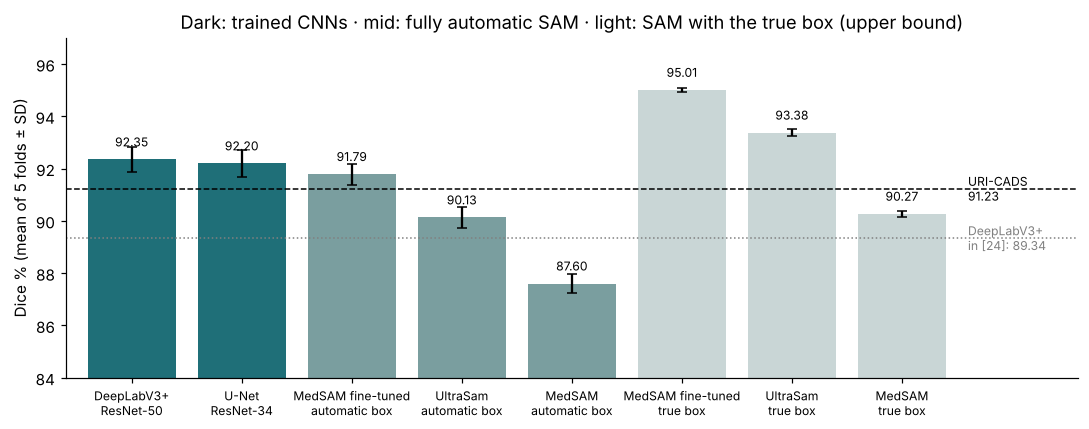

fold,0,1,2,3,4
DeepLabV3+ ResNet-50,92.56,92.22,91.59,92.61,92.79
U-Net ResNet-34,92.32,92.25,91.43,92.88,92.13
"MedSAM fine-tuned, automatic box",91.80,91.84,91.23,92.36,91.73
"UltraSam, automatic box",90.45,90.11,89.59,90.63,89.88
"MedSAM, automatic box",87.62,88.05,87.20,87.83,87.33
"MedSAM fine-tuned, true box",95.00,95.01,94.90,95.13,95.01
"UltraSam, true box",93.58,93.21,93.29,93.39,93.41
"MedSAM, true box",90.26,90.46,90.21,90.14,90.30


In [29]:
order = ["deeplabv3p_r50", "unet_r34", "medsam_ft_auto", "ultrasam_auto", "medsam_auto",
         "medsam_ft_gt", "ultrasam_gt", "medsam_gt"]
per_img = {m: pd.read_csv(C.SEG_DIR / m / "per_image.csv", dtype={"image_id": str}) for m in order}
fold_means = pd.DataFrame({m: d.groupby("fold").dice.mean() * 100 for m, d in per_img.items()})

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(order))
colors = ["#1f6f78"] * 2 + ["#7a9e9f"] * 3 + ["#c9d6d6"] * 3
ax.bar(x, fold_means.mean(), yerr=fold_means.std(ddof=1), color=colors, capsize=3)
for xi, v in zip(x, fold_means.mean()): ax.text(xi, v + 0.5, f"{v:.2f}", ha="center", fontsize=8)
ax.axhline(91.23, color="k", ls="--", lw=1); ax.text(7.6, 91.23, "URI-CADS\n91.23", va="center", fontsize=8)
ax.axhline(89.34, color="grey", ls=":", lw=1); ax.text(7.6, 89.34, "DeepLabV3+\nin [24]: 89.34", va="center", fontsize=8, color="grey")
ax.set_xticks(x, [MODEL_NAMES[m].replace(", ", "\n").replace(" ResNet", "\nResNet") for m in order], fontsize=8)
ax.set(xlim=(-0.6, 8.6), ylim=(84, 97), ylabel="Dice % (mean of 5 folds ± SD)",
       title="Dark: trained CNNs · mid: fully automatic SAM · light: SAM with the true box (upper bound)")
plt.tight_layout(); plt.show()

display(fold_means.rename(columns=MODEL_NAMES).round(2).T)

**Figure 6.1. The whole distribution, not only the average.** One box per model, over the 1,985 images: the box covers the middle half of the images, the line inside is the median, the dots are single images. The averages above hide how often a model fails badly; this shows it.

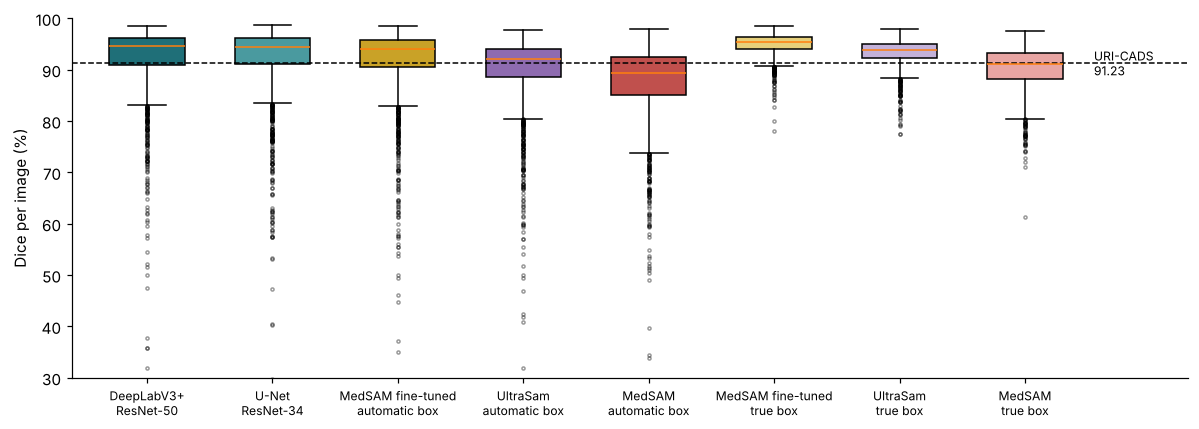

In [30]:
fig, ax = plt.subplots(figsize=(11, 4))
data = [per_img[m].dice * 100 for m in order]
bp = ax.boxplot(data, patch_artist=True, widths=.6, showfliers=True, flierprops=dict(markersize=2, alpha=.4))
for patch, m in zip(bp["boxes"], order): patch.set_facecolor(PALETTE[m])
ax.axhline(91.23, color="k", ls="--", lw=1); ax.text(8.55, 91.23, "URI-CADS\n91.23", va="center", fontsize=8); ax.set_xlim(0.4, 9.3)
ax.set_xticks(range(1, len(order) + 1), [MODEL_NAMES[m].replace(", ", "\n").replace(" ResNet", "\nResNet") for m in order], fontsize=8)
ax.set(ylabel="Dice per image (%)", ylim=(30, 100)); plt.tight_layout(); plt.show()

**Table 6.1. How often each model fails.** Share of the 1,985 images with a Dice below 0.90, 0.80 and 0.70, and HD95 above 50 px (border more than 50 px off).

In [31]:
rows = []
for m in order:
    d = per_img[m]
    rows.append({"model": MODEL_NAMES[m], "Dice < 0.90 (%)": (d.dice < .9).mean() * 100, "Dice < 0.80 (%)": (d.dice < .8).mean() * 100,
                 "Dice < 0.70 (%)": (d.dice < .7).mean() * 100, "HD95 > 50 px (%)": (d.hd95 > 50).mean() * 100,
                 "median Dice": d.dice.median() * 100})
pd.DataFrame(rows).set_index("model").round(1)

,Dice < 0.90 (%),Dice < 0.80 (%),Dice < 0.70 (%),HD95 > 50 px (%),median Dice
model,,,,,
DeepLabV3+ ResNet-50,21.6,4.8,1.5,7.9,94.6
U-Net ResNet-34,21.3,5.5,1.9,7.8,94.4
"MedSAM fine-tuned, automatic box",21.7,6.0,2.2,7.1,94.1
"UltraSam, automatic box",32.4,7.1,2.3,7.7,92.1
"MedSAM, automatic box",53.9,11.8,3.3,9.8,89.4
"MedSAM fine-tuned, true box",2.4,0.1,0.0,0.2,95.5
"UltraSam, true box",8.4,0.3,0.0,1.0,93.8
"MedSAM, true box",39.5,2.3,0.1,1.5,91.0


**Figure 6.2. All three scores together** (mean of the 5 folds ± SD). IoU tells the same story as Dice. HD95 (lower is better) shows that, given the true box, fine-tuned MedSAM and UltraSam also draw the most accurate borders; among the fully automatic models, the CNNs and fine-tuned MedSAM are equal.

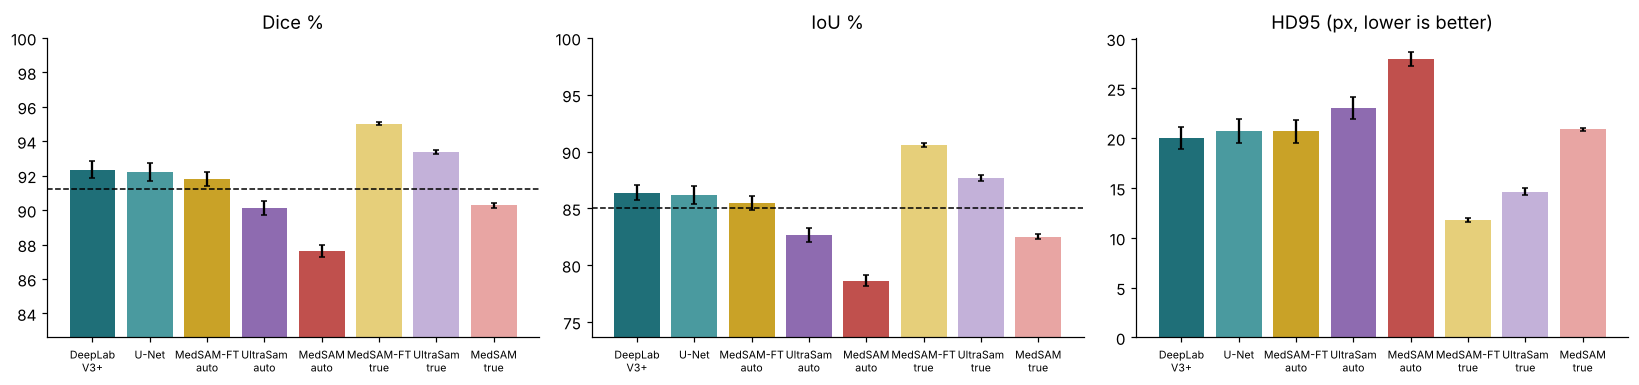

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (metric, lab, base) in zip(axes, [("dice", "Dice %", 91.23), ("iou", "IoU %", 84.99), ("hd95", "HD95 (px, lower is better)", None)]):
    fm = pd.DataFrame({m: per_img[m].groupby("fold")[metric].mean() * (1 if metric == "hd95" else 100) for m in order})
    ax.bar(range(len(order)), fm.mean(), yerr=fm.std(ddof=1), color=[PALETTE[m] for m in order], capsize=2)
    if base: ax.axhline(base, color="k", ls="--", lw=1)
    ax.set_xticks(range(len(order)), ["DeepLab\nV3+", "U-Net", "MedSAM-FT\nauto", "UltraSam\nauto", "MedSAM\nauto",
                                      "MedSAM-FT\ntrue", "UltraSam\ntrue", "MedSAM\ntrue"], fontsize=7)
    ax.set_title(lab); lo = fm.mean().min()
    if metric != "hd95": ax.set_ylim(lo - 5, 100)
plt.tight_layout(); plt.show()

**Figure 6.3. Fold by fold.** Each line is one model across the 5 test folds. A model that beats the baseline in every fold, not only on average, is a more solid result.

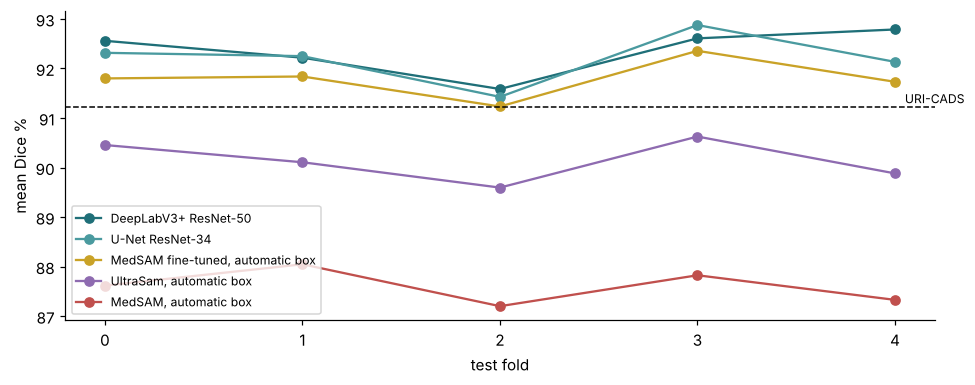

In [33]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for m in ["deeplabv3p_r50", "unet_r34", "medsam_ft_auto", "ultrasam_auto", "medsam_auto"]:
    ax.plot(fold_means.index, fold_means[m], marker="o", color=PALETTE[m], label=MODEL_NAMES[m])
ax.axhline(91.23, color="k", ls="--", lw=1); ax.text(4.05, 91.3, "URI-CADS", fontsize=8)
ax.set(xticks=range(5), xlabel="test fold", ylabel="mean Dice %"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Is DeepLabV3+ really better than U-Net, or is it noise?** Both models scored the same 1,985 images, so we bootstrap the per-image difference [S27].

In [34]:
def paired(a, b):
    d = per_img[a].set_index("image_id").dice - per_img[b].set_index("image_id").dice
    lo, hi = bootstrap_ci(d.values * 100)
    return {"A": MODEL_NAMES[a], "B": MODEL_NAMES[b], "mean Dice difference A-B (points)": d.mean() * 100,
            "95% CI": f"[{lo:.2f}, {hi:.2f}]", "A better on % of images": (d > 0).mean() * 100}

display(pd.DataFrame([paired("deeplabv3p_r50", "unet_r34"), paired("deeplabv3p_r50", "medsam_ft_auto"),
                      paired("medsam_ft_auto", "medsam_auto"), paired("ultrasam_auto", "medsam_auto")]).round(2))

,A,B,mean Dice difference A-B (points),95% CI,A better on % of images
0,DeepLabV3+ ResNet-50,U-Net ResNet-34,0.15,"[-0.04, 0.36]",51.99
1,DeepLabV3+ ResNet-50,"MedSAM fine-tuned, automatic box",0.56,"[0.34, 0.78]",60.86
2,"MedSAM fine-tuned, automatic box","MedSAM, automatic box",4.19,"[4.01, 4.38]",88.92
3,"UltraSam, automatic box","MedSAM, automatic box",2.53,"[2.37, 2.70]",77.03


**Figure 6.4. Do U-Net and DeepLabV3+ fail on the same images?** Each dot is one image. Dots near the diagonal are images both networks found equally easy or hard; dots far from it are images where only one of them failed.

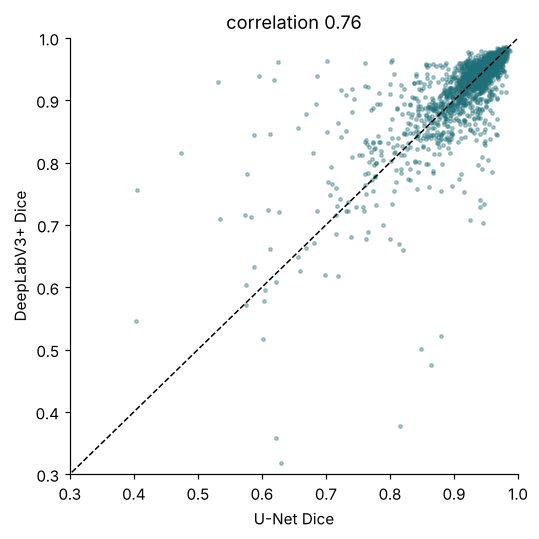

In [35]:
both = pd.DataFrame({"unet": un.dice, "deeplab": dl.dice}).dropna()
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(both.unet, both.deeplab, s=5, alpha=.35, color="#1f6f78"); ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlim=(.3, 1), ylim=(.3, 1), xlabel="U-Net Dice", ylabel="DeepLabV3+ Dice")
ax.set_title(f"correlation {both.corr().iloc[0, 1]:.2f}"); plt.tight_layout(); plt.show()

## 7. Where the models fail

We join the per-image Dice with the labels of dataset A and look at subgroups. URI-CADS reported that its errors concentrate on low-contrast kidneys, HC and PCD [24].

In [36]:
lab = labels_a.set_index("image_id")
groups = {
    "all": lab.index,
    "healthy": lab.index[lab.diagnosis == 0], "pathological": lab.index[lab.diagnosis == 1],
    "PCD": lab.index[lab.pcd == 1], "HC": lab.index[lab.hc == 1],
    "no PCD and no HC": lab.index[(lab.pcd == 0) & (lab.hc == 0)],
    "view 0 (93 %)": lab.index[lab.view == 0], "view 1 (7 %)": lab.index[lab.view == 1],
}
rows = []
for g, ids in groups.items():
    r = {"subgroup": g, "images": len(ids)}
    for m in ["deeplabv3p_r50", "unet_r34", "medsam_ft_auto"]:
        r[MODEL_NAMES[m]] = per_img[m].set_index("image_id").dice.reindex(ids).mean() * 100
    rows.append(r)
sub = pd.DataFrame(rows).set_index("subgroup").round(2)
sub

,images,DeepLabV3+ ResNet-50,U-Net ResNet-34,"MedSAM fine-tuned, automatic box"
subgroup,,,,
all,1985,92.35,92.20,91.79
healthy,450,93.91,93.81,93.38
pathological,1535,91.89,91.73,91.33
PCD,595,91.55,91.24,90.96
HC,509,90.67,90.48,90.11
no PCD and no HC,1276,92.83,92.71,92.26
view 0 (93 %),1842,92.62,92.55,92.16
view 1 (7 %),143,88.88,87.75,87.07


**Figure 7.1.** The subgroup table as a chart, with 95 % confidence intervals (bootstrap over images). Bars that do not overlap with "no PCD and no HC" are real differences, not chance.

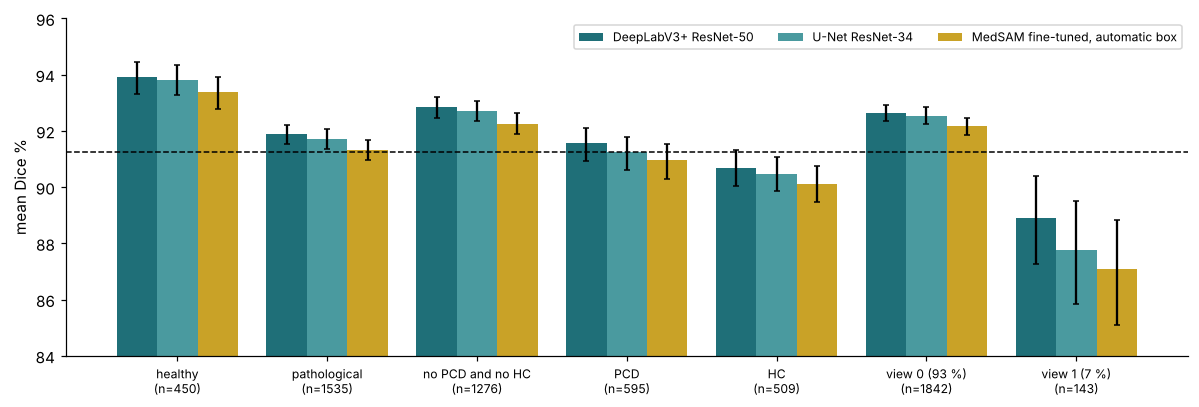

In [37]:
order_g = ["healthy", "pathological", "no PCD and no HC", "PCD", "HC", "view 0 (93 %)", "view 1 (7 %)"]
fig, ax = plt.subplots(figsize=(11, 3.8))
w = .27
for k, m in enumerate(["deeplabv3p_r50", "unet_r34", "medsam_ft_auto"]):
    s = per_img[m].set_index("image_id").dice
    means, errs = [], []
    for g in order_g:
        v = s.reindex(groups[g]).dropna().values * 100
        lo, hi = bootstrap_ci(v, n_boot=1000); means.append(v.mean()); errs.append([v.mean() - lo, hi - v.mean()])
    ax.bar(np.arange(len(order_g)) + (k - 1) * w, means, w, yerr=np.array(errs).T, capsize=2, color=PALETTE[m], label=MODEL_NAMES[m])
ax.axhline(91.23, color="k", ls="--", lw=1)
ax.set_xticks(range(len(order_g)), [f"{g}\n(n={len(groups[g])})" for g in order_g], fontsize=8)
ax.set(ylim=(84, 96), ylabel="mean Dice %"); ax.legend(fontsize=8, ncol=3, loc="upper right"); plt.tight_layout(); plt.show()

**Figure 7.2. Does kidney size matter?** Mean Dice of DeepLabV3+ for kidneys grouped by size (share of the image). The smallest kidneys are clearly the hardest (a few pixels of error weigh more when the kidney itself is small). The very largest are also slightly worse, and have the largest border errors (HD95).

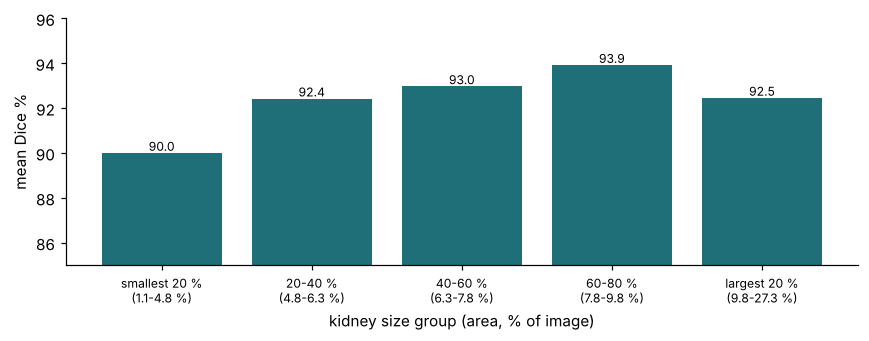

,kidney_area_pct,mean_dice,dice_below_090_pct,median_hd95
size group,,,,
smallest 20 %,1.1-4.8,90.0,32.2,12.6
20-40 %,4.8-6.3,92.4,20.7,11.4
40-60 %,6.3-7.8,93.0,17.9,12.6
60-80 %,7.8-9.8,93.9,12.6,12.0
largest 20 %,9.8-27.3,92.5,24.7,18.4


In [38]:
dd = dl[["dice", "hd95"]].join(chk.set_index("image_id").area_frac)
dd["size group"] = pd.qcut(dd.area_frac * 100, 5, labels=["smallest 20 %", "20-40 %", "40-60 %", "60-80 %", "largest 20 %"])
t = dd.groupby("size group", observed=True).agg(kidney_area_pct=("area_frac", lambda s: f"{s.min() * 100:.1f}-{s.max() * 100:.1f}"),
                                                mean_dice=("dice", lambda s: s.mean() * 100), dice_below_090_pct=("dice", lambda s: (s < .9).mean() * 100),
                                                median_hd95=("hd95", "median"))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(5), t.mean_dice, color="#1f6f78")
for i, v in enumerate(t.mean_dice): ax.text(i, v + .1, f"{v:.1f}", ha="center", fontsize=8)
ax.set_xticks(range(5), [f"{i}\n({a} %)" for i, a in zip(t.index, t.kidney_area_pct)], fontsize=8)
ax.set(ylim=(85, 96), ylabel="mean Dice %", xlabel="kidney size group (area, % of image)"); plt.tight_layout(); plt.show()
display(t.round(1))

**Table 7.1. Does the type of lesion matter?** Mean Dice of DeepLabV3+ on images that contain each lesion type (an image can contain several types). Complicated cysts (CCY) are the hardest: almost half of these images score below 0.90. Simple cysts (SCY) and stones (LIT) are also below average, while hydronephrosis (HYD) and pyramids (PYR) cause no extra difficulty.

In [39]:
rows = []
for code, name in C.BOX_CLASSES.items():
    ids = [i for i in labels_a.image_id[labels_a.n_boxes > 0] if any(b[4] == code for b in load_label_a(i).boxes)]
    v = dl.dice.reindex(ids).dropna()
    rows.append({"lesion type": name, "images": len(v), "mean Dice %": v.mean() * 100, "Dice < 0.90 (%)": (v < .9).mean() * 100})
rows.append({"lesion type": "no lesion box", "images": int((labels_a.n_boxes == 0).sum()),
             "mean Dice %": dl.dice.reindex(labels_a.image_id[labels_a.n_boxes == 0]).mean() * 100,
             "Dice < 0.90 (%)": (dl.dice.reindex(labels_a.image_id[labels_a.n_boxes == 0]) < .9).mean() * 100})
pd.DataFrame(rows).set_index("lesion type").round(1)

,images,mean Dice %,Dice < 0.90 (%)
lesion type,,,
LIT,87,91.5,27.6
SCY,595,91.1,29.9
CCY,79,87.6,44.3
PYR,161,94.5,10.6
ANG,33,94.2,9.1
SRM,11,92.3,18.2
HYD,469,92.6,20.9
CT,102,91.9,26.5
CE,38,94.3,10.5


Worst 8


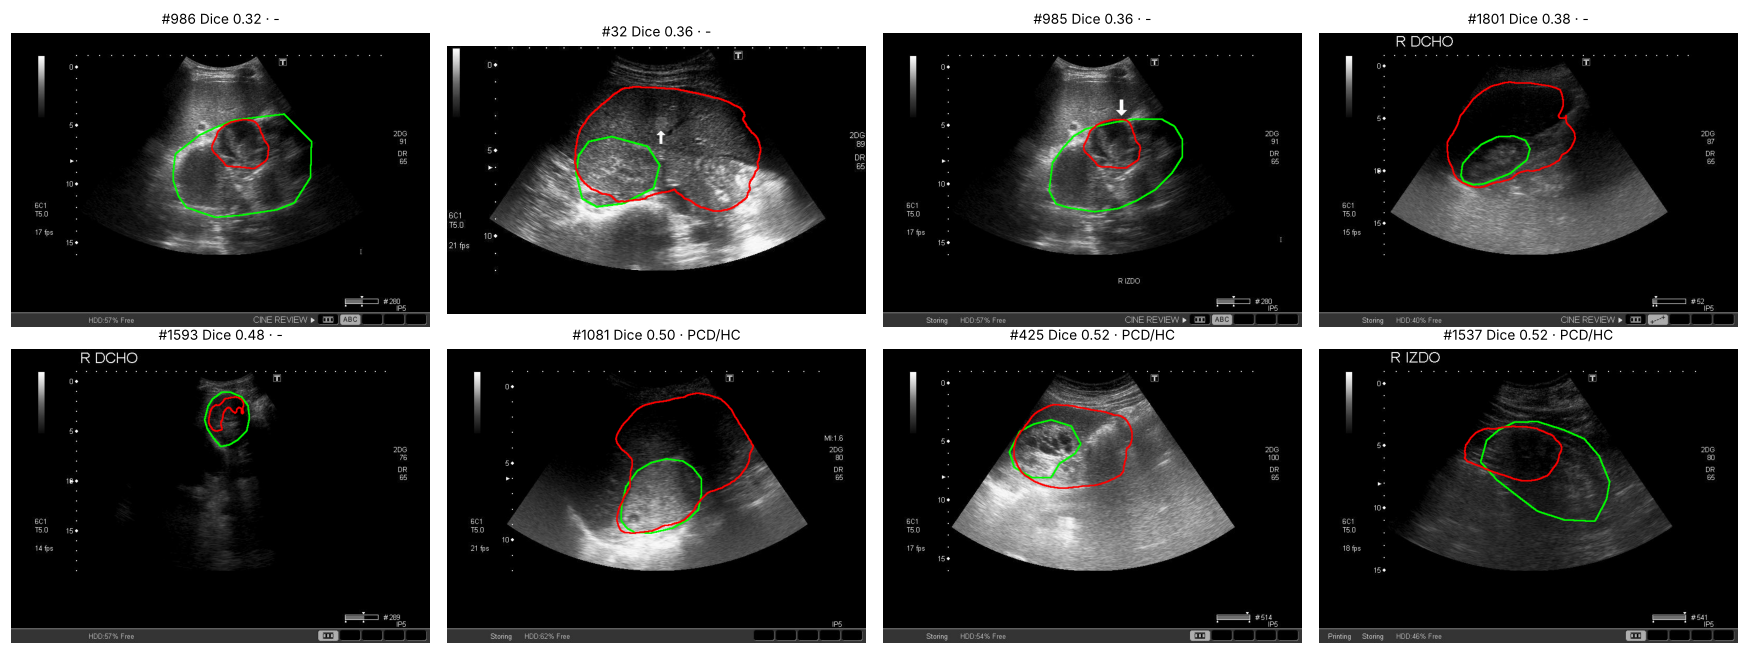

Typical (around the median)


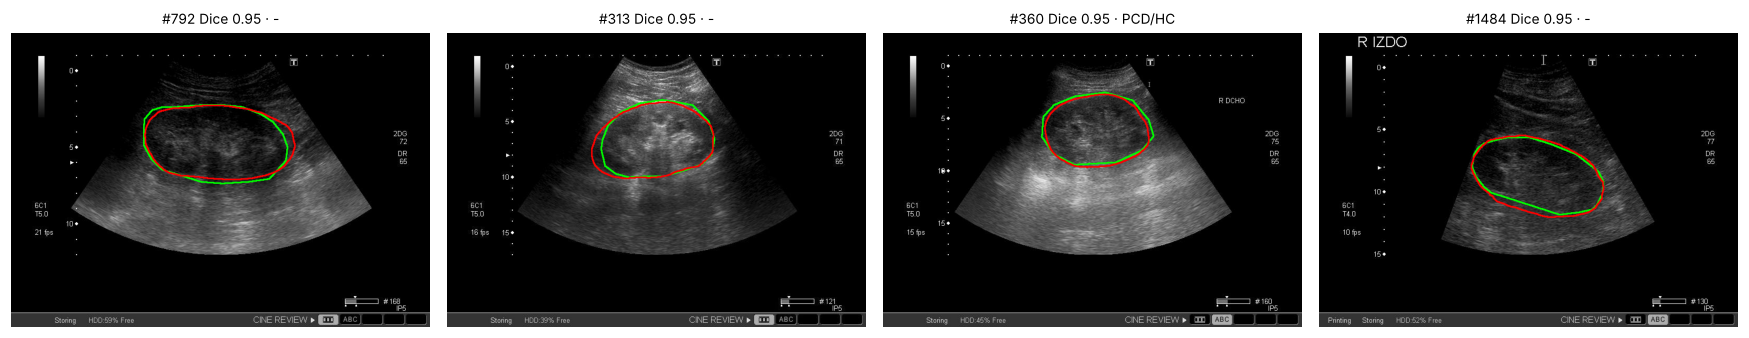

In [40]:
# Lowest-Dice images for DeepLabV3+ (green = reference, red = prediction)
d = per_img["deeplabv3p_r50"].sort_values("dice")
def pred_mask(model, iid):
    return (cv2.imread(str(C.PRED_MASKS / model / f"{iid}.png"), cv2.IMREAD_GRAYSCALE) > 0).astype(np.uint8)
def panel(ids, model="deeplabv3p_r50"):
    ims, tts = [], []
    for iid in ids:
        l = load_label_a(iid)
        ims.append(overlay(load_image_a(iid), load_mask_a(iid), pred=pred_mask(model, iid)))
        flags = [n for n, v in [("PCD", l.pcd), ("HC", l.hc)] if v] or ["-"]
        tts.append(f"#{iid} Dice {per_img[model].set_index('image_id').dice[iid]:.2f} · {'/'.join(flags)}")
    show(ims, tts)
print("Worst 8"); panel(d.image_id.head(8).tolist())
print("Typical (around the median)"); mid = len(d) // 2; panel(d.image_id.iloc[mid - 2: mid + 2].tolist())

**Figure 7.3. What kind of mistake?** For every image we split the error into **missed kidney** (blue in Figure 2.2: under-segmentation) and **extra area** (red: over-segmentation), each as a share of the true kidney area. Images where DeepLabV3+ scores below 0.85 are highlighted, and counted by type in the matrix on the right.

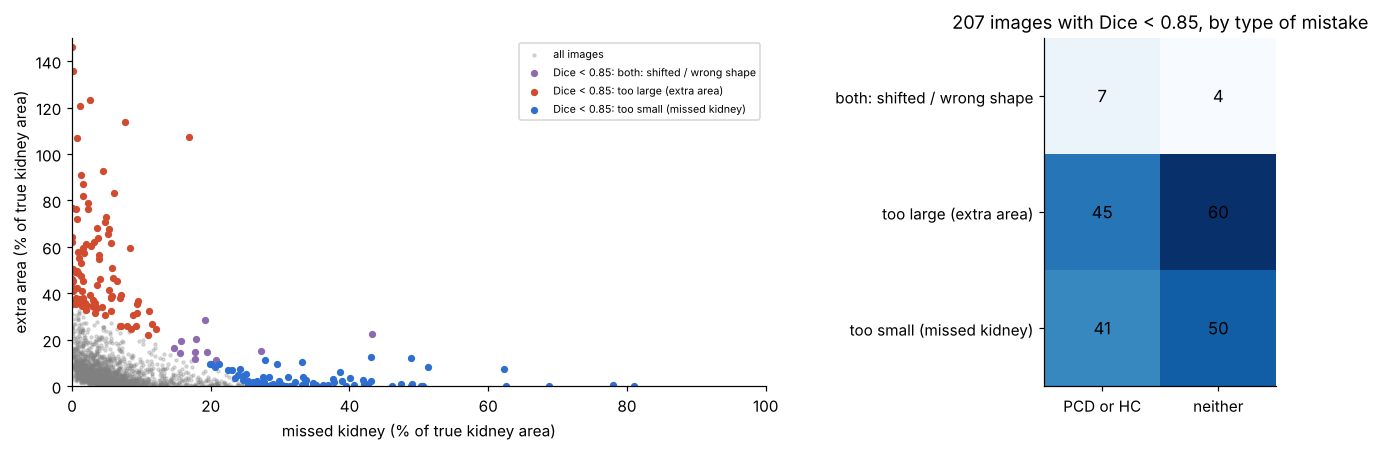

In [41]:
rows = []
for iid in labels_a.image_id:
    g, p = load_mask_a(iid).astype(bool), load_pred("deeplabv3p_r50", iid).astype(bool)
    rows.append({"image_id": iid, "missed": (g & ~p).sum() / g.sum(), "extra": (p & ~g).sum() / g.sum(),
                 "overlap_any": bool((g & p).any())})
err = pd.DataFrame(rows).set_index("image_id").join(dl.dice)
bad = err[err.dice < .85].copy()
def kind(r):
    if not r.overlap_any or (r.missed > .5 and r.extra > .5): return "wrong place"
    if r.missed > 2 * r.extra: return "too small (missed kidney)"
    if r.extra > 2 * r.missed: return "too large (extra area)"
    return "both: shifted / wrong shape"
bad["type"] = bad.apply(kind, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].scatter(err.missed * 100, err.extra * 100, s=4, alpha=.25, color="grey", label="all images")
cols = {"too small (missed kidney)": "#2f6fd1", "too large (extra area)": "#d14b2f", "both: shifted / wrong shape": "#8e6bb0", "wrong place": "black"}
for k, g in bad.groupby("type"):
    axes[0].scatter(g.missed * 100, g.extra * 100, s=14, color=cols[k], label=f"Dice < 0.85: {k}")
axes[0].set(xlabel="missed kidney (% of true kidney area)", ylabel="extra area (% of true kidney area)", xlim=(0, 100), ylim=(0, 150))
axes[0].legend(fontsize=7)
mat = pd.crosstab(bad.type, bad.index.map(lambda i: "PCD or HC" if (lab_idx.pcd[i] or lab_idx.hc[i]) else "neither"))
im = axes[1].imshow(mat.values, cmap="Blues"); axes[1].set_xticks(range(mat.shape[1]), mat.columns); axes[1].set_yticks(range(mat.shape[0]), mat.index)
for (i, j), v in np.ndenumerate(mat.values): axes[1].text(j, i, v, ha="center", va="center", fontsize=11)
axes[1].set_title(f"{len(bad)} images with Dice < 0.85, by type of mistake")
plt.tight_layout(); plt.show()

**Figure 7.4. One example of each kind of mistake** (the worst image of each type). Colours as in Figure 2.2.

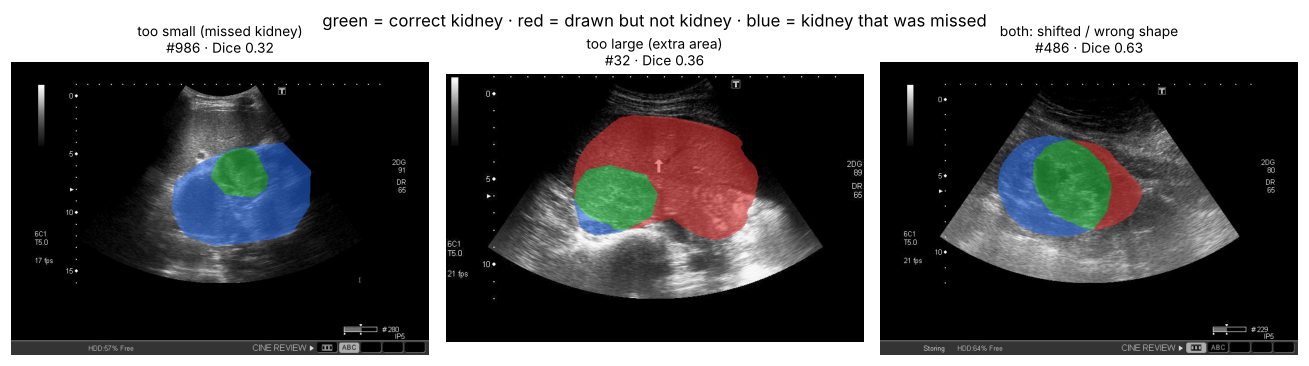

In [42]:
ims, tts = [], []
for k in cols:
    g = bad[bad.type == k]
    if len(g) == 0: continue
    iid = g.dice.idxmin()
    ims.append(error_overlay(load_image_a(iid), load_mask_a(iid), load_pred("deeplabv3p_r50", iid)))
    tts.append(f"{k}\n#{iid} · Dice {g.dice[iid]:.2f}")
show_rgb(ims, tts, ncols=len(ims), suptitle=ERROR_LEGEND)

**Figure 7.5. Do all models find the same images hard?** Left: correlation of per-image Dice between models (1 = they rank images in exactly the same order). Right: of the 100 hardest images for each model, how many are shared between each pair of models. The automatic-box foundation models share many hard images with the U-Net because their box comes from the U-Net: when the U-Net misses the kidney, they inherit the mistake. UltraSam with the true box finds quite different images hard.

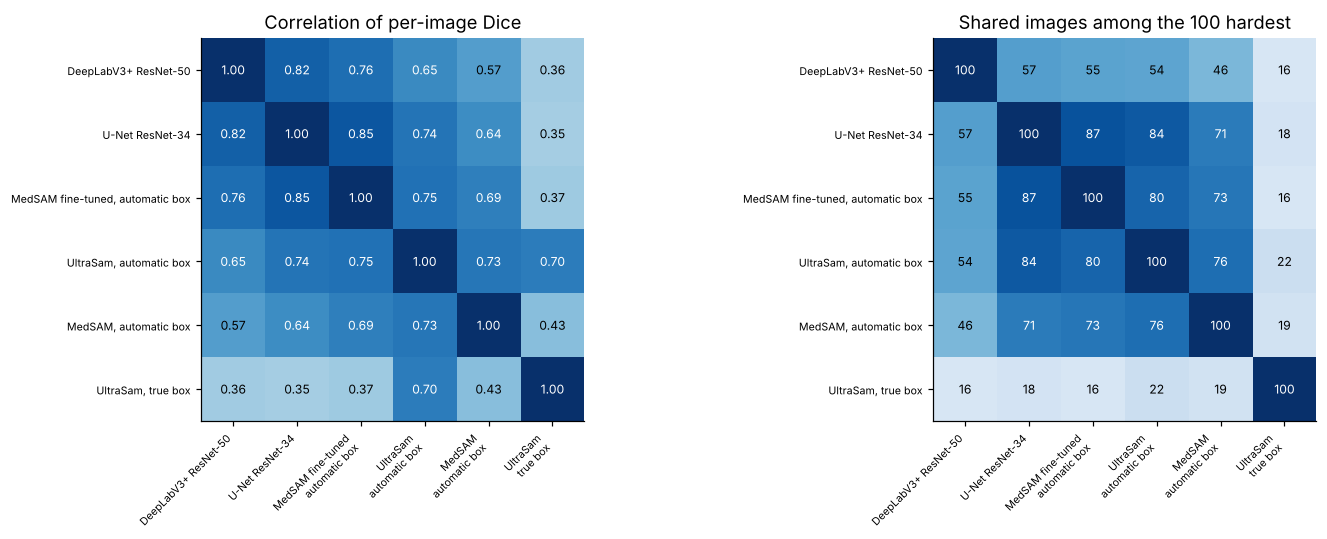

Images among the 100 hardest for DeepLabV3+, U-Net and fine-tuned MedSAM at once: 53


In [43]:
allm = ["deeplabv3p_r50", "unet_r34", "medsam_ft_auto", "ultrasam_auto", "medsam_auto", "ultrasam_gt"]
D = pd.DataFrame({MODEL_NAMES[m]: per_img[m].set_index("image_id").dice for m in allm})
worst = {c: set(D[c].nsmallest(100).index) for c in D.columns}
shared = pd.DataFrame([[len(worst[a] & worst[b]) for b in D.columns] for a in D.columns], index=D.columns, columns=D.columns)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, M_, t, fmt in [(axes[0], D.corr(method="spearman"), "Correlation of per-image Dice", "{:.2f}"),
                       (axes[1], shared, "Shared images among the 100 hardest", "{:d}")]:
    ax.imshow(M_.values, cmap="Blues", vmin=0)
    ax.set_xticks(range(len(M_)), [c.replace(", ", "\n") for c in M_.columns], fontsize=7, rotation=45, ha="right")
    ax.set_yticks(range(len(M_)), M_.index, fontsize=7); ax.set_title(t)
    hi = M_.values.max()
    for (i, j), v in np.ndenumerate(M_.values):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if v > .6 * hi else "black")
plt.tight_layout(); plt.show()
hard_all = set.intersection(*[worst[MODEL_NAMES[m]] for m in ["deeplabv3p_r50", "unet_r34", "medsam_ft_auto"]])
print(f"Images among the 100 hardest for DeepLabV3+, U-Net and fine-tuned MedSAM at once: {len(hard_all)}")

**What we see.**

When the model gets an image badly wrong, it is usually for one of two reasons. Sometimes it finds the kidney
but **draws only its middle part** and misses the outer edge, as in images #985 and #986. Other times it
**draws too much**, spilling over into the tissue next to the kidney, which can look very similar on ultrasound
(images #32, #1801, #1081 and #425). These are the exceptions: the typical images, shown in the second panel,
are outlined almost exactly like the doctors' outlines.

Some kidneys are harder than others. When the kidney's outer layer is unusually bright (HC) or when its inner and
outer layers are hard to tell apart (PCD), the kidney blends into its surroundings and its edge is harder to see.
Our best model scores about 2 points lower on HC kidneys (90.7 %) and about 1 point lower on PCD kidneys (91.6 %)
than on kidneys with neither problem (92.8 %). URI-CADS reports the same weak spot [24]. The model also does
worse on the less common view, which makes up only 7 % of the images: 88.9 % against 92.6 % for the main view,
probably because it had far fewer examples of it to learn from.

One detail when reading the list of worst cases: #985 and #986 are two almost identical frames from the same
scan, so they count as one difficult case rather than two.

## 8. External test on KidneyUS

All models trained on dataset A are run, without any change, on the KidneyUS images (`src/kidney/eval_external.py`). For the CNNs we average the 5 fold models (`ens`). For MedSAM and UltraSam the box comes from the true capsule (`gt`) or from the CNN prediction (`auto`).

For the CNN ensemble the 5 fold models' probabilities are averaged, then thresholded at 0.5 and post-processed as in section 3. Images, box rules and thresholds are otherwise identical to dataset A.

Because KidneyUS outlines follow the real border while dataset A outlines are ellipse-like, every prediction is also scored against **an ellipse fitted to the KidneyUS capsule** (`dice_ellipse`). If a model only loses Dice because of outline style, its ellipse score would be clearly higher.

In [44]:
if RUN_PIPELINE:
    subprocess.run([sys.executable, "-m", "kidney.eval_external", "--models", "unet_r34", "deeplabv3p_r50",
                    "medsam", "ultrasam", "medsam_ft"] + ([SMK] if SMK else []), check=True)
ext = pd.read_csv(C.SEG_DIR / "external" / "external_summary.csv")
names = {("unet_r34", "ens"): "U-Net ResNet-34 (5-fold ensemble)", ("deeplabv3p_r50", "ens"): "DeepLabV3+ ResNet-50 (5-fold ensemble)",
         ("medsam", "auto"): "MedSAM, automatic box", ("ultrasam", "auto"): "UltraSam, automatic box",
         ("medsam_ft", "auto"): "MedSAM fine-tuned, automatic box", ("medsam", "gt"): "MedSAM, true box",
         ("ultrasam", "gt"): "UltraSam, true box", ("medsam_ft", "gt"): "MedSAM fine-tuned, true box"}
e = ext[ext.subset == "all"].copy()
e["model "] = [names.get((m, b)) for m, b in zip(e.model, e.member)]
e = e.dropna(subset=["model "]).set_index("model ")
e = e[["n", "dice", "dice_ci", "dice_ellipse", "hd95_median"]]
e[["dice", "dice_ellipse"]] *= 100
e.loc["published KidneyUS baseline [18]"] = [np.nan, 85.0, "", np.nan, np.nan]
e.round(2)

,n,dice,dice_ci,dice_ellipse,hd95_median
model,,,,,
U-Net ResNet-34 (5-fold ensemble),487.0,90.19,"[0.890, 0.912]",89.61,29.41
DeepLabV3+ ResNet-50 (5-fold ensemble),487.0,90.54,"[0.895, 0.914]",89.95,29.07
"MedSAM, automatic box",487.0,89.53,"[0.884, 0.905]",88.84,35.36
"MedSAM, true box",487.0,93.27,"[0.927, 0.937]",91.98,23.60
"UltraSam, automatic box",487.0,91.13,"[0.900, 0.921]",89.16,25.10
"UltraSam, true box",487.0,95.20,"[0.947, 0.955]",92.56,16.49
"MedSAM fine-tuned, automatic box",487.0,89.60,"[0.884, 0.906]",89.50,31.00
"MedSAM fine-tuned, true box",487.0,94.02,"[0.935, 0.944]",93.62,21.08
published KidneyUS baseline [18],NaN,85.00,,NaN,NaN


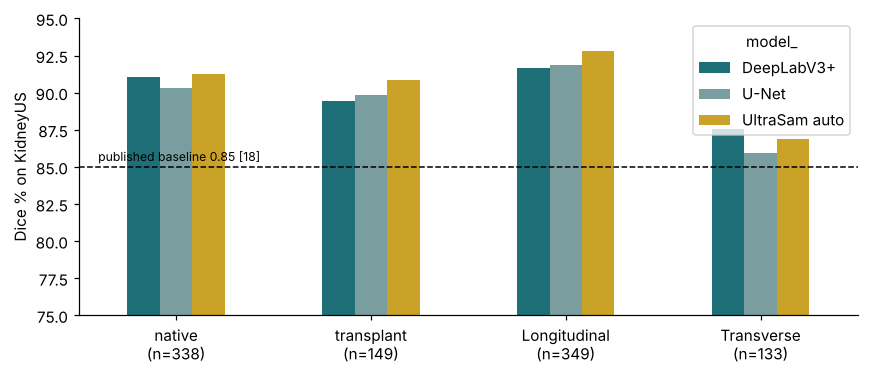

In [45]:
sel = ext[(ext.model.isin(["unet_r34", "deeplabv3p_r50"]) & (ext.member == "ens")) |
          ((ext.model == "ultrasam") & (ext.member == "auto"))]
sel = sel[sel.subset.str.startswith(("view=Longitudinal", "view=Transverse", "kidney_type"))]
sel = sel.assign(model_=sel.model.map({"unet_r34": "U-Net", "deeplabv3p_r50": "DeepLabV3+", "ultrasam": "UltraSam auto"}))
pt = sel.pivot_table(index="subset", columns="model_", values="dice") * 100
n = sel.drop_duplicates("subset").set_index("subset").n
ax = pt.plot.bar(figsize=(8, 3.5), rot=0, color=["#1f6f78", "#7a9e9f", "#c9a227"])
ax.axhline(85, color="k", ls="--", lw=1); ax.text(-0.4, 85.4, "published baseline 0.85 [18]", fontsize=8)
ax.set_xticklabels([f"{s.split('=')[1]}\n(n={n[s]})" for s in pt.index]); ax.set(ylim=(75, 95), ylabel="Dice % on KidneyUS", xlabel="")
plt.tight_layout(); plt.show()

**Figure 8.1. Dataset A versus KidneyUS, image by image.** Distribution of the per-image Dice of the DeepLabV3+ models on their own test folds (dataset A) and on KidneyUS (5-fold average). The shift to the left is the price of a new hospital and new scanners.

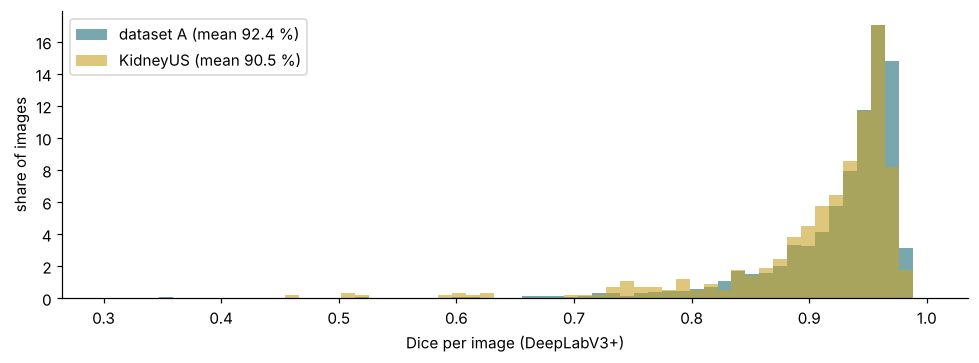

In [46]:
ext_img = {m: pd.read_csv(C.SEG_DIR / "external" / f"{m}_per_image.csv") for m in ["unet_r34", "deeplabv3p_r50", "medsam", "ultrasam", "medsam_ft"]}
dlb = ext_img["deeplabv3p_r50"].query("member == 'ens'").merge(meta_b, on="filename")
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.linspace(.3, 1, 60)
ax.hist(dl.dice, bins=bins, density=True, alpha=.6, color="#1f6f78", label=f"dataset A (mean {dl.dice.mean() * 100:.1f} %)")
ax.hist(dlb.dice, bins=bins, density=True, alpha=.6, color="#c9a227", label=f"KidneyUS (mean {dlb.dice.mean() * 100:.1f} %)")
ax.set(xlabel="Dice per image (DeepLabV3+)", ylabel="share of images"); ax.legend(); plt.tight_layout(); plt.show()

**Figure 8.2. Every model on every KidneyUS subgroup.** Rows are models, columns are subgroups; each cell is the mean Dice (%). Darker = better. The transverse column is the weak spot for the CNNs and for every model that uses the automatic box. With the true box, the foundation models outline transverse kidneys as well as longitudinal ones. So the problem with transverse images is **finding** the kidney, not **drawing** its outline.

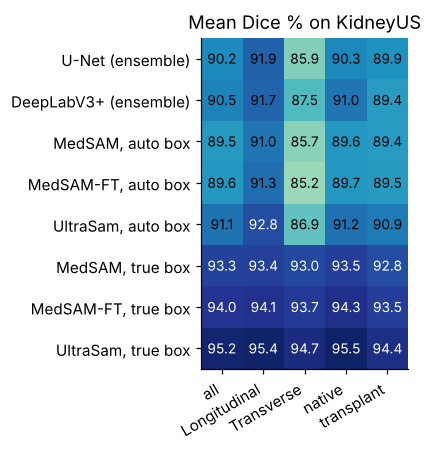

In [47]:
mk = {("unet_r34", "ens"): "U-Net (ensemble)", ("deeplabv3p_r50", "ens"): "DeepLabV3+ (ensemble)",
      ("medsam", "auto"): "MedSAM, auto box", ("medsam_ft", "auto"): "MedSAM-FT, auto box", ("ultrasam", "auto"): "UltraSam, auto box",
      ("medsam", "gt"): "MedSAM, true box", ("medsam_ft", "gt"): "MedSAM-FT, true box", ("ultrasam", "gt"): "UltraSam, true box"}
subs = ["all", "view=Longitudinal", "view=Transverse", "kidney_type=native", "kidney_type=transplant"]
H = pd.DataFrame({lab_: {s: ext[(ext.model == m) & (ext.member == b) & (ext.subset == s)].dice.iloc[0] * 100 for s in subs}
                  for (m, b), lab_ in mk.items()}).T
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.imshow(H.values, cmap="YlGnBu", vmin=80, vmax=96)
ax.set_xticks(range(len(subs)), [s.split("=")[-1] for s in subs], rotation=30, ha="right"); ax.set_yticks(range(len(H)), H.index)
for (i, j), v in np.ndenumerate(H.values): ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9, color="white" if v > 92.5 else "black")
ax.set_title("Mean Dice % on KidneyUS"); plt.tight_layout(); plt.show()

**Figure 8.3. Is the drawing style to blame?** Each dot is one KidneyUS image, scored against the sonographer's real outline (x) and against a smooth ellipse fitted to it (y). If our smooth, dataset-A-style outlines were penalised for their style, the dots would sit above the diagonal. They sit on the diagonal or slightly below it, so the drawing style is not what costs us on KidneyUS.

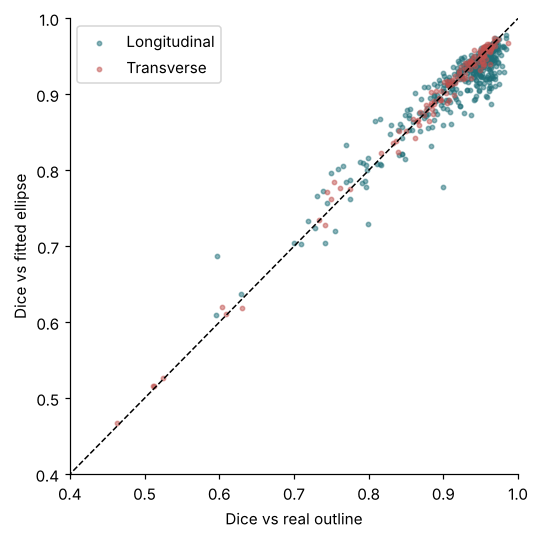

In [48]:
fig, ax = plt.subplots(figsize=(5, 5))
for v, col in [("Longitudinal", "#1f6f78"), ("Transverse", "#c0504d")]:
    g = dlb[dlb.view == v]; ax.scatter(g.dice, g.dice_ellipse, s=8, alpha=.5, color=col, label=v)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set(xlim=(.4, 1), ylim=(.4, 1), xlabel="Dice vs real outline", ylabel="Dice vs fitted ellipse")
ax.legend(); plt.tight_layout(); plt.show()

**Figure 8.4. A first look at the transverse problem.** Left: Dice against kidney size on KidneyUS, by view. Right: mean Dice by view within the same size range. If transverse images only fail because their kidneys are smaller, the two views should score the same once size is matched. They do in one size group but not in the others, so size explains only part of the gap.

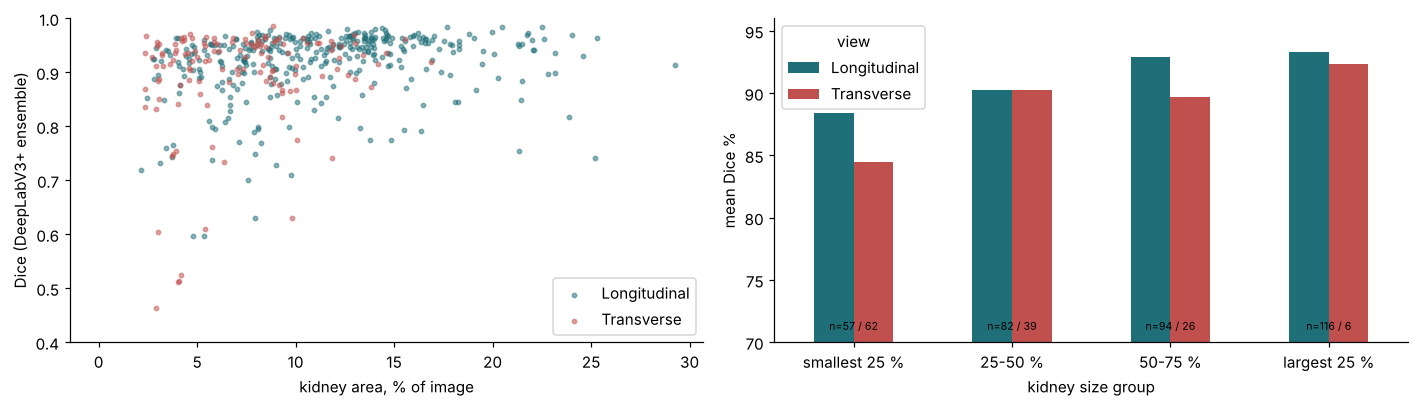

view,Longitudinal,Transverse
size group,,
smallest 25 %,88.4,84.4
25-50 %,90.3,90.3
50-75 %,92.9,89.7
largest 25 %,93.3,92.3


In [49]:
dlb["size group"] = pd.qcut(dlb.area_frac * 100, 4, labels=["smallest 25 %", "25-50 %", "50-75 %", "largest 25 %"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for v, col in [("Longitudinal", "#1f6f78"), ("Transverse", "#c0504d")]:
    g = dlb[dlb.view == v]; axes[0].scatter(g.area_frac * 100, g.dice, s=8, alpha=.5, color=col, label=v)
axes[0].set(xlabel="kidney area, % of image", ylabel="Dice (DeepLabV3+ ensemble)", ylim=(.4, 1)); axes[0].legend()
pt2 = dlb[dlb.view.isin(["Longitudinal", "Transverse"])].pivot_table(index="size group", columns="view", values="dice", aggfunc="mean", observed=True) * 100
cnt = dlb[dlb.view.isin(["Longitudinal", "Transverse"])].pivot_table(index="size group", columns="view", values="dice", aggfunc="size", observed=True)
pt2.plot.bar(ax=axes[1], rot=0, color=["#1f6f78", "#c0504d"]); axes[1].set(ylim=(70, 96), ylabel="mean Dice %", xlabel="kidney size group")
for i, (idx, r) in enumerate(cnt.iterrows()):
    axes[1].text(i, 71, f"n={int(r.get('Longitudinal', 0))} / {int(r.get('Transverse', 0))}", ha="center", fontsize=7)
plt.tight_layout(); plt.show()
display(pt2.round(1))

**Table 8.1. Is the transverse gap a general weakness, or a few complete misses?** For each view: the mean and the median Dice, the number of images where the model **missed the kidney completely** (Dice below 0.10), and the mean once those are left out. If the medians are close but the means are not, a handful of complete misses is pulling the transverse mean down.

In [50]:
rows = []
for (m, b), name in [(("deeplabv3p_r50", "ens"), "DeepLabV3+ (ensemble)"), (("unet_r34", "ens"), "U-Net (ensemble)"),
                     (("ultrasam", "auto"), "UltraSam, auto box"), (("ultrasam", "gt"), "UltraSam, true box")]:
    d = ext_img[m].query("member == @b").merge(meta_b, on="filename")
    for v in ["Longitudinal", "Transverse"]:
        g = d[d.view == v]
        rows.append({"model": name, "view": v, "images": len(g), "mean Dice %": g.dice.mean() * 100,
                     "median Dice %": g.dice.median() * 100, "complete misses (Dice < 0.10)": int((g.dice < .1).sum()),
                     "mean without misses %": g[g.dice >= .1].dice.mean() * 100})
pd.DataFrame(rows).set_index(["model", "view"]).round(1)

images  mean Dice %  median Dice %  \
model                 view                                               
DeepLabV3+ (ensemble) Longitudinal     349         91.7           93.9   
                      Transverse       133         87.5           92.9   
U-Net (ensemble)      Longitudinal     349         91.9           94.0   
                      Transverse       133         85.9           92.5   
UltraSam, auto box    Longitudinal     349         92.8           94.9   
                      Transverse       133         86.9           93.7   
UltraSam, true box    Longitudinal     349         95.4           95.9   
                      Transverse       133         94.7           95.5   

                                    complete misses (Dice < 0.10)  \
model                 view                                          
DeepLabV3+ (ensemble) Longitudinal                              0   
                      Transverse                                3   
U-Net (ensemble)      Longitudinal                              0   
                      Transverse                                6   
UltraSam, auto box    Longitudinal                              0   
                      Transverse                                6   
UltraSam, true box    Longitudinal                              0   
                      Transverse                                1   

                                    mean without misses %  
model                 view                                 
DeepLabV3+ (ensemble) Longitudinal                   91.7  
                      Transverse                     89.5  
U-Net (ensemble)      Longitudinal                   91.9  
                      Transverse                     90.0  
UltraSam, auto box    Longitudinal                   92.8  
                      Transverse                     91.0  
UltraSam, true box    Longitudinal                   95.4  
                      Transverse                     95.4

**Figure 8.5. The hardest KidneyUS images** for DeepLabV3+, with the sonographer's outline in green. The predicted outlines for KidneyUS are not stored by the pipeline (only their scores), so this shows which images are hard, not how the model failed on them. A Dice of 0.00 means the predicted outline does not touch the kidney at all: the model outlined something else. The three images scoring 0.51–0.52 are almost identical frames of the same patient, so they are one hard case, not three.

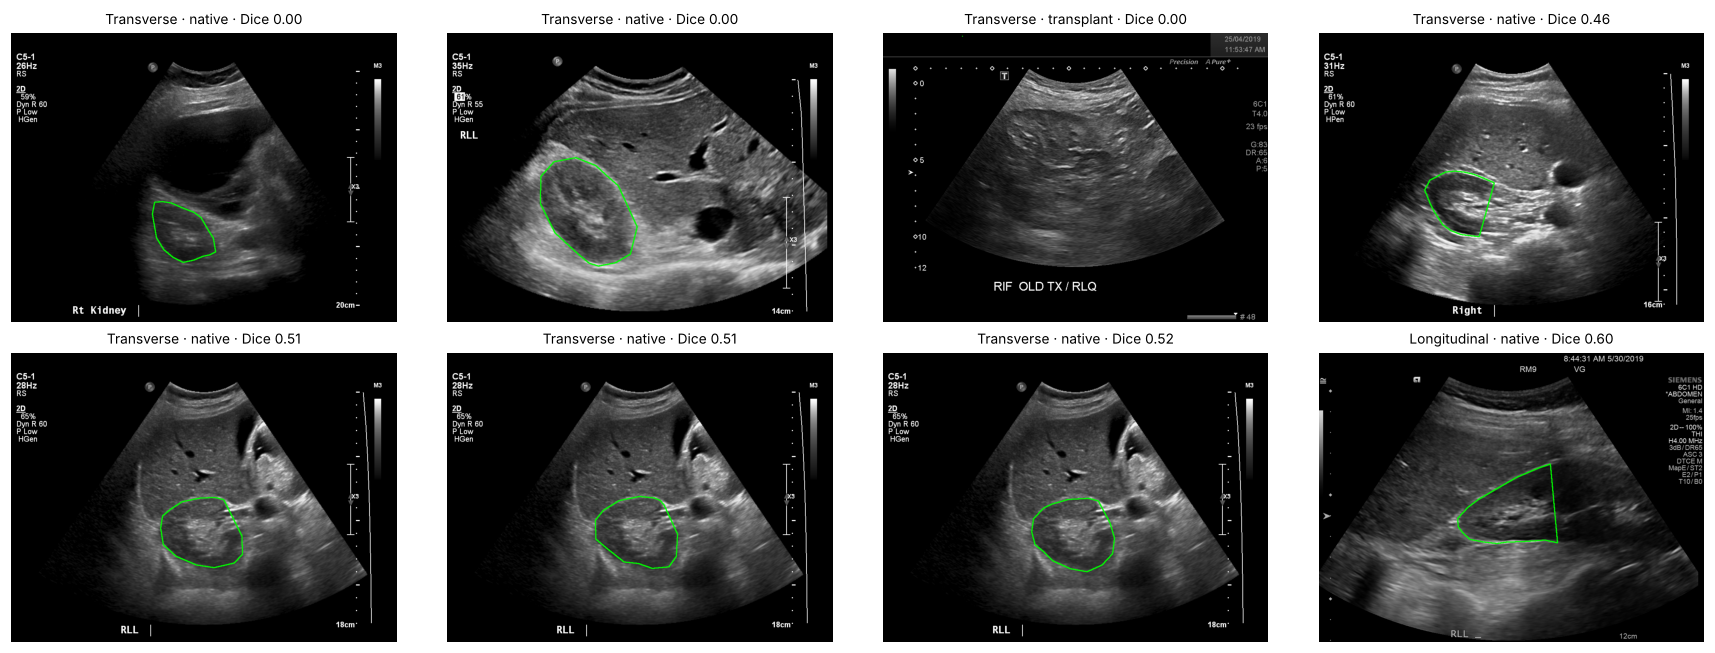

In [51]:
ims, tts = [], []
for r in dlb.nsmallest(8, "dice").itertuples():
    ims.append(overlay(load_image_b(r.filename), load_capsule_b(r.filename)))
    tts.append(f"{r.view} · {r.kidney_type} · Dice {r.dice:.2f}")
show(ims, tts)

**What we see.**

This is the real test of whether the models learned "what a kidney looks like" or just "what a kidney looks like
in this one hospital". They were trained only on images from Hospital Ramón y Cajal, all taken with the same
Toshiba scanner, and here they meet images from another hospital and several other scanners for the first time.
They hold up well: the fully automatic models score between 89.5 % and 91.1 % on KidneyUS (DeepLabV3+ 90.5 %,
UltraSam with the automatic box 91.1 %), above the 85 % published for this dataset [18].

We expected a drop for another reason too. The outlines in our training data are smooth and ellipse-like, while the
KidneyUS outlines follow the true, irregular kidney border, so even a perfect model would lose a little overlap.
To check how much this matters, we also scored every prediction against a smooth ellipse fitted to each KidneyUS
outline. The scores hardly change (DeepLabV3+: 90.5 % against the real outline, 90.0 % against the ellipse), so
the difference in drawing style is not what holds the models back.

The weak spot is the view. On transverse images (a cross-section of the kidney) the CNNs reach 86–88 %, against
about 92 % on longitudinal images (the kidney seen lengthwise). This is unexpected: according to URI-CADS [24],
most of our training images are transverse, so the models should have plenty of practice with this view. We
have not yet found out why, and it is one of the points we will investigate.

Finally, KidneyUS includes 149 transplanted kidneys, which do not appear in our training data at all. The models
outline them almost as well as native kidneys (U-Net: 89.9 % against 90.3 %).

## Summary figure

One picture of the whole chapter: each model's mean Dice on dataset A (left of each pair) and on KidneyUS (right), against the URI-CADS baseline on dataset A and the published KidneyUS baseline. The trained models lose about 2 points on the new hospital. The automatic-box foundation models score slightly higher on KidneyUS than on dataset A, possibly because they follow the real kidney border, as the KidneyUS outlines do.

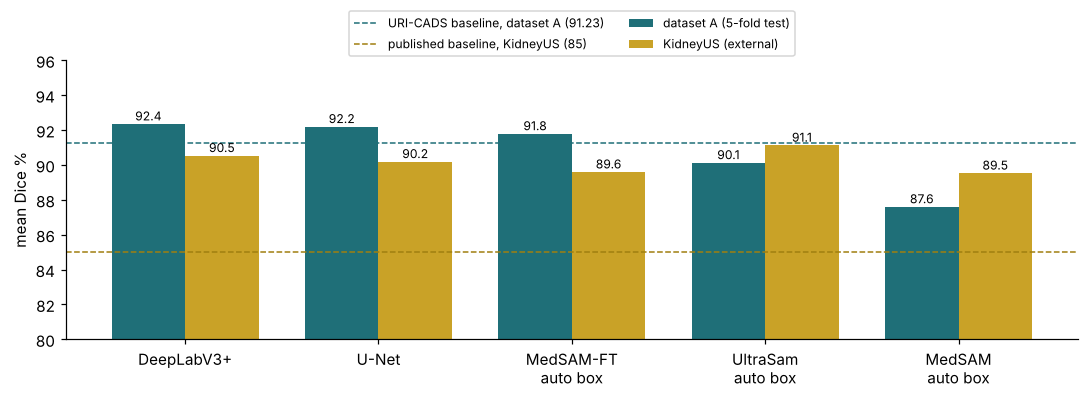

In [52]:
summ = [("DeepLabV3+", "deeplabv3p_r50", ("deeplabv3p_r50", "ens")), ("U-Net", "unet_r34", ("unet_r34", "ens")),
        ("MedSAM-FT\nauto box", "medsam_ft_auto", ("medsam_ft", "auto")), ("UltraSam\nauto box", "ultrasam_auto", ("ultrasam", "auto")),
        ("MedSAM\nauto box", "medsam_auto", ("medsam", "auto"))]
a_vals = [per_img[m].dice.mean() * 100 for _, m, _ in summ]
b_vals = [ext[(ext.model == k[0]) & (ext.member == k[1]) & (ext.subset == "all")].dice.iloc[0] * 100 for _, _, k in summ]
fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(summ)); w = .38
ax.bar(x - w / 2, a_vals, w, color="#1f6f78", label="dataset A (5-fold test)")
ax.bar(x + w / 2, b_vals, w, color="#c9a227", label="KidneyUS (external)")
for xi, a, b in zip(x, a_vals, b_vals):
    ax.text(xi - w / 2, a + .2, f"{a:.1f}", ha="center", fontsize=8); ax.text(xi + w / 2, b + .2, f"{b:.1f}", ha="center", fontsize=8)
ax.axhline(91.23, color="#1f6f78", ls="--", lw=1, label="URI-CADS baseline, dataset A (91.23)")
ax.axhline(85, color="#a07f10", ls="--", lw=1, label="published baseline, KidneyUS (85)")
ax.set_xticks(x, [s[0] for s in summ]); ax.set(ylim=(80, 96), ylabel="mean Dice %")
ax.legend(loc="upper center", fontsize=8, ncol=2, bbox_to_anchor=(0.5, 1.2))
plt.tight_layout(); plt.show()

## 9. Conclusions

**1. Our models outline the kidney better than the published baseline.**
URI-CADS, the system built on the same images, reached an average Dice of 91.23 %. Both of our trained networks
do better: DeepLabV3+ reaches 92.35 % and U-Net 92.20 %. The improvement is small but reliable: it is the same
in every fold, and the baseline falls outside the range of values we would expect from chance (95 % confidence
interval). The gap is clearest for DeepLabV3+, the same network URI-CADS trained as a reference: theirs scored
89.34 %, ours 92.35 %, about 3 points more. We changed several things in the training (how images are resized,
the loss, longer training, the final clean-up), and we have not yet tested which of them makes the difference.

**2. U-Net and DeepLabV3+ are equally good.**
DeepLabV3+ is ahead by only 0.15 points, too little to be sure it is really better. Either one can serve as the
kidney model for the rest of the project. We suggest DeepLabV3+, because it is also slightly better on the
external data.

**3. Ready-made foundation models work well, but only if someone tells them where the kidney is.**
Without any training on our data, UltraSam outlines the kidney better than any of our networks (93.38 %) when it
is given the exact box around the kidney. When the box comes from our own model instead, as it would for a new
patient, it drops to 90.13 %. MedSAM shows the same pattern (90.27 % → 87.60 %). Retraining only the small part
of MedSAM that draws the outline, which takes a few minutes, fixes most of this: the fully automatic version
rises to 91.79 %, above the baseline.

**4. The models also work on images from another hospital.**
On KidneyUS, a dataset from another hospital and other scanners that the models never saw during training, the
fully automatic models reach 89.5–91.1 %, above the 85 % published for that dataset. URI-CADS did not test on
external data, so this is new. The one weak point there is the transverse view, which we still need to explain.

**5. Our models struggle with the same images as URI-CADS.**
The hardest cases are kidneys whose edge is hard to see (HC and PCD), images where nearby tissue looks like
kidney, and the less common view. URI-CADS reports the same difficulties, so these appear to be hard cases in the
data rather than flaws of one particular model.

### Limitations

**1. Training data from a single source.** All training images come from one hospital and one scanner (a Toshiba
Xario 660a), taken between 2009 and 2018. The good result on KidneyUS is encouraging, but it is one other
dataset. We cannot yet say how the models behave on other machines, on handheld probes, or on images taken by
less experienced operators in primary care, which is the setting this project is aimed at.

**2. Unbalanced views.** About 93 % of the training images show one view (transverse, according to URI-CADS
[24]) and only 143 images (7 %) show the other. The models are clearly weaker on the rare view (88.9 % against
92.6 %). Also, our label files only code the view as 0 or 1; that 0 means transverse is our reading of the
paper, not something the labels state.

**3. An unexplained drop on transverse images in KidneyUS.** On the external data the models do worst on
transverse images (86–88 % against about 92 %), even though this is the view they saw most in training. We have
not found the cause yet. Possible explanations, still to be checked, are differences in how the two hospitals
acquire this view, or the smaller size of the kidney in cross-section, where a few pixels of error weigh more.

**4. The reference outlines are smooth approximations.** The doctors' outlines in our data are polygons drawn over
an ellipse, smoother than the real kidney border. Very high scores (above about 93 %) therefore partly measure
how well a model copies this drawing style, not only how well it finds the true border. The ellipse check on
KidneyUS suggests this effect is small, but it limits how far the numbers can be interpreted.

**5. The split was corrected after our runs.** These results use the team's earlier split. The corrected split
changes the scores very little (only one pair of images was affected), but our predicted outlines must be
regenerated on the corrected split before the classifier can use them.

**6. We did not test which training choice causes the gain.** Our CNNs beat the URI-CADS DeepLabV3+ by about
3 points, but we changed several things at once (letterboxing, loss, longer training, post-processing). We do not
know which of them matters most.

**7. No clinical review.** All scores compare our outlines with one set of reference outlines. No clinician has
looked at our predicted outlines, so we cannot say whether the differences matter in practice, or whether some
"errors" are in fact closer to the true border than the reference.

### Next steps

The next steps stay within kidney segmentation. They are ordered by priority: first what the rest of the team
needs from us, then improvements that answer the limitations above, then extensions.

**A. Needed by the team**

1. **Retrain on the corrected split.** Use `folds_corrected.csv`, with the validation images taken from
   `nested_cv_splits.csv`, and regenerate the predicted outlines for all 1,985 images. This takes about 5–6 hours
   on one GPU (U-Net, DeepLabV3+ and the MedSAM fine-tuning).
2. **Hand the DeepLabV3+ outlines to the classification team.** They replace the doctors' `.mat` outlines now used
   for the kidney-focused classifier in notebook 05 (a new patient will not have a doctor's outline), and they
   are needed for the test of whether Grad-CAM looks at the kidney.

**B. Improve the models, aimed at the weaknesses we found**

Each change is tested on its own, under the same 5 folds, so we know what each one contributes (limitation 6).

3. **Augmentation that imitates other scanners.** Our current augmentation moves and resizes the image but barely
   changes how ultrasound looks. We will add random changes in overall brightness (gain), brightness that varies
   with depth, speckle-like noise, blur, simulated shadows and random changes to the shape of the scan fan. The
   aim is to make the model less tied to the Toshiba scanner. We judge it mainly on KidneyUS, especially the
   transverse view (limitations 1 and 3).
4. **Give the rare view more weight.** Show the 143 images of the less common view more often during training, so
   the model gets more practice on it (limitation 2).
5. **A loss that rewards the right border.** Add a boundary-aware term to the loss, so the model is penalised for
   misplacing the edge, not only for missing area. We judge it mainly on HD95, which measures exactly this.
6. **Fine-tune UltraSam.** UltraSam was the best model without any training. We will retrain its outline-drawing
   part on our data, exactly as we did for MedSAM in section 5. This reuses our existing code.
7. **Ultrasound-pretrained encoders.** Replace the ImageNet encoder of the U-Net with one pretrained on ultrasound
   (USFM [S2], UltraFedFM [S5], SonoBase [S6] or OpenUS [S7]) and compare.
8. **Find out why transverse images fail on KidneyUS.** Look at the failed images, compare kidney size and image
   settings between the two datasets for this view, and check whether points 3 and 4 help (limitation 3).

**C. Extensions**

9. **Lesion outlines.** Give MedSAM and UltraSam the 2,478 lesion boxes as prompts to outline each lesion,
   starting with cysts and hydronephrosis, the clearest types (`plan.md`, Phase 4).
10. **Kidney size.** Measure kidney length and area in centimetres from the predicted outline and the depth scale
    printed on each image.

**D. Clinical review**

11. **Ask a clinician to check a sample.** Kidney outlines can be scored against the doctors' outlines, but only a
    clinician can say whether our "errors" matter, or whether some are closer to the true border than the reference
    (limitation 7). Lesion outlines (point 9) have no reference at all, so they cannot be reported without a
    review. About 50–100 images are enough: the worst cases, a random sample, and the lesion outlines. We will
    arrange this through our supervisor.

## References

Full entries in `Documents/references.md`.

- **[24]** Molina-Moreno M. et al. URI-CADS: A Fully Automated Computer-Aided Diagnosis System for Ultrasound Renal Imaging. *J Imaging Inform Med* 2024. doi:10.1007/s10278-024-01055-4
- **[18]** Singla R. et al. The Open Kidney Ultrasound Data Set. arXiv:2206.06657
- **[12], [19], [22]** Athavale 2020; Lien 2023; Alkhaldi 2026: U-Net-family kidney segmentation in the literature review
- **[S1]** UltraSam, arXiv:2411.16222 · **[S3]** MedSAM, *Nat Commun* 2024
- **[S17]** ResNet · **[S18]** U-Net · **[S19]** segmentation_models_pytorch · **[S21]** MONAI
- **[S24]** Dice loss (V-Net) · **[S25]** scikit-learn · **[S27]** bootstrap · **[S29]** HD95 · **[S30]** AdamW